<a href="https://colab.research.google.com/github/drcrajc/all_cancer_ai/blob/main/ALL_SR_Revision_PostLock_Inference_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ALL microscopy — Scientific Reports revision: post-lock inference analyses (v3)

Prepared for Dr. Cyril Robinson Azariah J.

**Scope of this notebook**

1. **The completed primary results are not changed.** The primary run folder is opened read-only. A write guard refuses any write inside it, and no model is trained, re-tuned or re-selected.
2. **C-NMC 2019 preliminary-test cohort (inference only).** This runs only after four audits pass: labels, patient identities, duplicate links (exact and near-duplicate screening, within the cohort and against all 10,661 training images), and provenance. A confirmation flag records that you inspected these audits before any prediction is made.
3. **Independent-acquisition dataset (Reviewer 2 Q5).** This is an optional slot that stays switched off until you supply a genuinely independent dataset (different centre and acquisition) with a manifest. The preliminary C-NMC cohort is from the same centre and protocol, so it does **not** resolve Q5. The notebook labels it accordingly.
4. **No learning curves.** The revision removes the data-efficiency claim.

Optional: compiled inference timing (off by default). It writes to the supplementary folder only.

**Run order:** GPU runtime → cells 1–8 → audit cells 9–12 → read the printed audits, set `PRELIM_PROVENANCE_CONFIRMED = True` (and `NEAR_DUPLICATES_REVIEWED = True` if near-duplicate candidates were flagged) in cell 2 → rerun cell 2 → cells 13–15 → (optional external cells) → summary and ZIP.

In [25]:
# 1. Mount Drive, imports, GPU check
from google.colab import drive
drive.mount('/content/drive')

import os, re, json, hashlib, gc, zipfile, itertools, platform, time
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score, average_precision_score, log_loss, roc_curve)
import tensorflow as tf
from tensorflow.keras import layers

GPUS = tf.config.list_physical_devices('GPU')
assert GPUS, 'Select Runtime > Change runtime type > GPU, then rerun.'
for g in GPUS:
    try: tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError: pass
print('TensorFlow', tf.__version__, '| Python', platform.python_version(), '| GPU',
      tf.config.experimental.get_device_details(GPUS[0]).get('device_name', GPUS[0].name))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow 2.21.0 | Python 3.13.16 | GPU NVIDIA L4


In [26]:
# 2. Configuration — keep identical across sessions
PRIMARY_ROOT = Path('/content/drive/MyDrive/leukemia_SR_revision_v1')                 # read-only
SUPP_ROOT    = Path('/content/drive/MyDrive/leukemia_SR_revision_v1_supplementary')   # all new outputs

# --- Preliminary-test cohort (C-NMC 2019, labelled preliminary phase) ---
CNMC_ROOT     = Path('/content/drive/MyDrive/leukemia_4model_run/data/raw/C-NMC_Leukemia')
PRELIM_DIR    = CNMC_ROOT / 'validation_data' / 'C-NMC_test_prelim_phase_data'
PRELIM_LABELS = CNMC_ROOT / 'validation_data' / 'C-NMC_test_prelim_phase_data_labels.csv'
# Documented composition (TCIA collection page, DOI 10.7937/tcia.2019.dc64i46r)
DOCUMENTED = {'images': 1867, 'images_ALL': 1219, 'images_HEM': 648, 'subjects': 28, 'subjects_ALL': 13, 'subjects_HEM': 15}
ACCEPT_COUNT_MISMATCH_REASON = ''      # leave blank; only fill if counts differ AND you have documented why

# Provenance — fill these in from your own records before confirming
PRELIM_SOURCE_DESCRIPTION = 'Kaggle mirror of the TCIA C-NMC 2019 release ("Leukemia Classification"), downloaded by the authors'
PRELIM_RETRIEVED_ON = '2026-05'      # your actual download month or date
PRELIM_PROVENANCE_CONFIRMED = True
NEAR_DUP_BITS = 12                     # 256-bit cell-crop dHash distance at or below which pairs are flagged for review
NEAR_DUPLICATES_REVIEWED = False       # set True after visually checking flagged pairs (only needed if any are flagged)
EXCLUDE_CONFIRMED_NEAR_DUPLICATES = [] # optional: preliminary relative paths you judged to be near-copies of training images

# --- Independent-acquisition dataset for Reviewer 2 Q5 (optional; off until supplied) ---
EXTERNAL_MANIFEST_CSV = ''             # CSV: path,label,patient_id,source,site,country,microscope,camera,stain,magnification,label_definition
EXTERNAL_NAME = ''                     # short name, e.g. 'ALL-IDB2'
EXTERNAL_PROVENANCE_CONFIRMED = False

RUN_COMPILED_LATENCY = False           # optional; writes to SUPP_ROOT/latency only

LOCAL_CACHE = Path('/content/image_cache'); LOCAL_CACHE.mkdir(exist_ok=True)
PRELIM_OUT = SUPP_ROOT / 'cnmc_preliminary'
EXTERNAL_OUT = SUPP_ROOT / 'external_independent'
print('Configuration set.')

Configuration set.


In [27]:
# 3. Utilities, with a guard that makes the primary folder read-only
def _guard(path):
    p = Path(path).resolve()
    assert not p.is_relative_to(PRIMARY_ROOT.resolve()), f'Refusing to write inside the primary run folder: {p}'
    return p
def now(): return datetime.now(timezone.utc).isoformat()
def digest(obj): return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()
def sha_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''): h.update(chunk)
    return h.hexdigest()
def atomic_json(path, obj):
    path = _guard(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp')
    with open(tmp, 'w') as f: json.dump(obj, f, indent=2, allow_nan=False, default=str)
    os.replace(tmp, path)
def atomic_csv(path, df):
    path = _guard(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp'); df.to_csv(tmp, index=False); os.replace(tmp, path)
def save_fig(fig, path, **kw):
    path = _guard(path); path.parent.mkdir(parents=True, exist_ok=True); fig.savefig(path, **kw)
def read_json(path): return json.loads(Path(path).read_text())
def load_pred(path):
    return pd.read_csv(path, dtype={'patient_id': str, 'original_patient_id': str, 'relative_path': str})
def pixel_hash(path):
    # Identical definition to the primary audit, so hashes are directly comparable.
    with Image.open(path) as im:
        a = np.asarray(ImageOps.exif_transpose(im).convert('RGB'))
    return hashlib.sha256(str(a.shape).encode() + a.tobytes()).hexdigest()
def cell_dhash(path, size=16):
    # 256-bit difference hash of the cell's bounding box (non-black pixels), for near-duplicate screening.
    with Image.open(path) as im:
        a = np.asarray(ImageOps.exif_transpose(im).convert('RGB'))
    mask = a.max(axis=2) > 10
    if mask.any():
        r, c = np.where(mask); a = a[r.min():r.max() + 1, c.min():c.max() + 1]
    g = np.asarray(Image.fromarray(a).convert('L').resize((size + 1, size), Image.BILINEAR), dtype=np.int16)
    return np.packbits((g[:, 1:] > g[:, :-1]).ravel())
def hamming(A, B):
    x = np.bitwise_xor(A[:, None, :], B[None, :, :])
    return np.bitwise_count(x).sum(axis=2) if hasattr(np, 'bitwise_count') else np.unpackbits(x, axis=2).sum(axis=2)
SUPP_ROOT.mkdir(parents=True, exist_ok=True)
print('Utilities ready; primary folder is write-protected.')

Utilities ready; primary folder is write-protected.


In [28]:
# 4. Load and verify frozen primary artifacts (read-only)
for f in ['protocol.json', 'FINAL_TEST_LOCK.json', 'selected_configs.json', 'ensemble_protocol.json', 'ensemble/meta.json',
          'splits/primary_manifest.csv', 'audit/raw_manifest.csv', 'final_test/all_metrics.csv']:
    assert (PRIMARY_ROOT / f).exists(), f'Missing primary artifact: {f}'
PROTOCOL = read_json(PRIMARY_ROOT / 'protocol.json')
assert digest(PROTOCOL['config']) == PROTOCOL['hash'], 'Primary protocol hash invalid.'
C = PROTOCOL['config']
SEEDS, MODELS, STRATEGIES = C['SEEDS'], C['MODELS'], C['STRATEGIES']
IMAGE_SIZE, BATCH_SIZE, BOOTSTRAPS, PERMUTATIONS = C['IMAGE_SIZE'], C['BATCH_SIZE'], C['BOOTSTRAPS'], C['PERMUTATIONS']
EP = read_json(PRIMARY_ROOT / 'ensemble_protocol.json'); ARM = EP['arms']
META = read_json(PRIMARY_ROOT / 'ensemble/meta.json'); assert META['features'] == MODELS and EP['threshold'] == 0.5
manifest = pd.read_csv(PRIMARY_ROOT / 'splits' / 'primary_manifest.csv',
                       dtype={'patient_id': str, 'original_patient_id': str, 'analysis_group_id': str, 'relative_path': str})
manifest['label'] = manifest.label.astype(int)
RAW_TRAIN = pd.read_csv(PRIMARY_ROOT / 'audit' / 'raw_manifest.csv', dtype=str); RAW_TRAIN['label'] = RAW_TRAIN.label.astype(int)
TEST = manifest[manifest.partition == 'test'].sort_values('relative_path').reset_index(drop=True)
MAIN_RUNS = sorted((PRIMARY_ROOT / 'tasks' / 'main').rglob('completed.json'))
assert len(MAIN_RUNS) == len(MODELS) * len(STRATEGIES) * len(SEEDS)
PRIMARY_FINGERPRINT = {f: sha_file(PRIMARY_ROOT / f) for f in
                       ['protocol.json', 'FINAL_TEST_LOCK.json', 'ensemble/meta.json', 'final_test/all_metrics.csv']}

# Training patient-ID schema (used to validate the preliminary cohort's IDs)
TRAIN_IDS = RAW_TRAIN[['patient_id', 'label']].drop_duplicates()
SCHEMA = {0: r'^[Hh]\d+$', 1: r'^\d+$'}
assert all(TRAIN_IDS[TRAIN_IDS.label == k].patient_id.str.match(v).all() for k, v in SCHEMA.items()), 'Training ID schema differs.'
print('Primary run: 24 main runs, arms', ARM, '| reference', EP['reference_model'])
print('Training IDs:', TRAIN_IDS.label.value_counts().to_dict(), '(HEM = H<digits>, ALL = <digits>)')

Primary run: 24 main runs, arms {'MobileNetV2': 'baseline', 'Xception': 'baseline', 'ResNet50': 'class_weighted', 'DenseNet121': 'baseline'} | reference ResNet50
Training IDs: {1: 47, 0: 26} (HEM = H<digits>, ALL = <digits>)


In [29]:
# 5. Load-only model support (registers the custom layer used in the saved checkpoints)
@tf.keras.utils.register_keras_serializable(package='ALLRevision')
class BackbonePreprocess(layers.Layer):
    def __init__(self, model_name, **kwargs):
        super().__init__(**kwargs); self.model_name = model_name
    def call(self, x):
        x = tf.cast(x, tf.float32)
        if self.model_name in ['MobileNetV2', 'Xception']: return x / 127.5 - 1.
        if self.model_name == 'DenseNet121':
            return (x / 255. - tf.constant([.485, .456, .406], tf.float32)) / tf.constant([.229, .224, .225], tf.float32)
        return tf.reverse(x, axis=[-1]) - tf.constant([103.939, 116.779, 123.68], tf.float32)
    def get_config(self): return {**super().get_config(), 'model_name': self.model_name}

def _load_image(path):
    # BILINEAR matches the original training/evaluation pipeline (verified by the reproduction diagnostic).
    with Image.open(path) as im:
        return np.asarray(ImageOps.exif_transpose(im).convert('RGB')
                          .resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR), dtype=np.uint8)
def image_array(paths, cache_name):
    f = LOCAL_CACHE / f'{cache_name}.npz'
    if f.exists():
        z = np.load(f, allow_pickle=True)
        if list(z['paths']) == list(paths): return z['x']
    x = np.stack([_load_image(p) for p in paths]); np.savez(f, x=x, paths=np.array(paths, dtype=object)); return x
def predict_array(model, x):
    ds = tf.data.Dataset.from_tensor_slices(x).map(lambda a: tf.cast(a, tf.float32)).batch(BATCH_SIZE)
    return model.predict(ds, verbose=0)[:, 1]
def prediction_frame(df, p):
    df = df.reset_index(drop=True)
    return pd.DataFrame({'relative_path': df.relative_path.astype(str), 'patient_id': df.patient_id.astype(str),
                         'original_patient_id': df.original_patient_id.astype(str), 'label': df.label.astype(int),
                         'p_all': p, 'prediction': (p >= .5).astype(int)})
def load_frozen(path): return tf.keras.models.load_model(path, compile=False)
def run_key(r): return f"{r['model']}__{r['strategy']}__seed{r['seed']}"
print('Model loading support ready.')

Model loading support ready.


In [30]:
# 6. Metrics and cluster-aware statistics (same definitions as the primary analysis)
CI_KEYS = ['accuracy', 'balanced_accuracy', 'macro_f1', 'sensitivity_all', 'specificity_hem', 'roc_auc', 'patient_mean_cell_accuracy']
def metrics(pred):
    y = pred.label.to_numpy(int); p = pred.p_all.to_numpy(float); q = (p >= .5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, q, labels=[0, 1]).ravel()
    pr, re_, f1, _ = precision_recall_fscore_support(y, q, labels=[0, 1], zero_division=0)
    pmca = pd.DataFrame({'g': pred.patient_id.to_numpy(), 'v': (y == q).astype(float)}).groupby('g').v.mean().mean()
    return {'accuracy': float(accuracy_score(y, q)), 'balanced_accuracy': float(balanced_accuracy_score(y, q)),
            'macro_precision': float(pr.mean()), 'macro_recall': float(re_.mean()), 'macro_f1': float(f1.mean()),
            'precision_all': float(pr[1]), 'precision_hem': float(pr[0]), 'f1_all': float(f1[1]), 'f1_hem': float(f1[0]),
            'sensitivity_all': float(tp / (tp + fn)), 'specificity_hem': float(tn / (tn + fp)),
            'roc_auc': float(roc_auc_score(y, p)), 'pr_auc_all': float(average_precision_score(y, p)),
            'log_loss': float(log_loss(y, np.column_stack([1 - p, p]), labels=[0, 1])),
            'patient_mean_cell_accuracy': float(pmca), 'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
            'n_images': int(len(pred)), 'n_patients': int(pred.original_patient_id.nunique()),
            'n_analysis_groups': int(pred.patient_id.nunique())}
def _core(y, p, gacc):
    q = (p >= .5).astype(int)
    tp = int(((q == 1) & (y == 1)).sum()); tn = int(((q == 0) & (y == 0)).sum())
    fp = int(((q == 1) & (y == 0)).sum()); fn = int(((q == 0) & (y == 1)).sum())
    sens, spec = tp / (tp + fn), tn / (tn + fp)
    f1a = 2 * tp / (2 * tp + fp + fn) if tp else 0.; f1h = 2 * tn / (2 * tn + fn + fp) if tn else 0.
    return {'accuracy': (tp + tn) / len(y), 'balanced_accuracy': (sens + spec) / 2, 'macro_f1': (f1a + f1h) / 2,
            'sensitivity_all': sens, 'specificity_hem': spec, 'roc_auc': roc_auc_score(y, p),
            'patient_mean_cell_accuracy': float(np.mean(gacc))}
def _prepare(pred):
    pred = pred.sort_values('relative_path').reset_index(drop=True); g = pred.patient_id.astype(str).to_numpy()
    idx = {k: np.flatnonzero(g == k) for k in np.unique(g)}
    strata = {c: np.array(sorted(pred.loc[pred.label == c, 'patient_id'].astype(str).unique())) for c in (0, 1)}
    return pred, idx, strata
def _draws(strata, n, seed=42):
    rng = np.random.default_rng(seed)
    for _ in range(n): yield np.concatenate([rng.choice(strata[c], size=len(strata[c]), replace=True) for c in (0, 1)])
def cluster_ci(pred, n=None):
    # Resamples whole analysis groups within class; all cells of a sampled group stay together.
    n = n or BOOTSTRAPS; pred, idx, strata = _prepare(pred)
    y = pred.label.to_numpy(int); p = pred.p_all.to_numpy(float); ok = ((p >= .5).astype(int) == y).astype(float)
    gacc = {k: ok[v].mean() for k, v in idx.items()}; vals = {k: [] for k in CI_KEYS}
    for ids in _draws(strata, n):
        sel = np.concatenate([idx[g] for g in ids]); m = _core(y[sel], p[sel], [gacc[g] for g in ids])
        for k in CI_KEYS: vals[k].append(m[k])
    est = metrics(pred)
    return {k: {'estimate': est[k], 'low': float(np.quantile(v, .025)), 'high': float(np.quantile(v, .975))} for k, v in vals.items()}
def paired_cluster(a, b, n=None, perms=None):
    n = n or BOOTSTRAPS; perms = perms or PERMUTATIONS
    a, idx, strata = _prepare(a); b = b.sort_values('relative_path').reset_index(drop=True)
    assert a.relative_path.equals(b.relative_path) and np.array_equal(a.label, b.label)
    y = a.label.to_numpy(int); pa = a.p_all.to_numpy(float); pb = b.p_all.to_numpy(float)
    oka = ((pa >= .5).astype(int) == y).astype(float); okb = ((pb >= .5).astype(int) == y).astype(float)
    ga = {k: oka[v].mean() for k, v in idx.items()}; gb = {k: okb[v].mean() for k, v in idx.items()}
    diffs = {k: [] for k in CI_KEYS}
    for ids in _draws(strata, n):
        sel = np.concatenate([idx[g] for g in ids])
        ma = _core(y[sel], pa[sel], [ga[g] for g in ids]); mb = _core(y[sel], pb[sel], [gb[g] for g in ids])
        for k in CI_KEYS: diffs[k].append(ma[k] - mb[k])
    ea, eb = metrics(a), metrics(b)
    sums = np.array([(oka[v] - okb[v]).sum() for v in idx.values()])
    observed = abs(sums.sum()); rng = np.random.default_rng(2026); extreme = 0
    for start in range(0, perms, 1000):
        k = min(1000, perms - start)
        extreme += int((np.abs((rng.choice([-1, 1], size=(k, len(sums))) * sums).sum(axis=1)) >= observed - 1e-12).sum())
    return {'difference_a_minus_b': {k: {'estimate': ea[k] - eb[k], 'low': float(np.quantile(v, .025)),
                                         'high': float(np.quantile(v, .975))} for k, v in diffs.items()},
            'cluster_permutation_p': float((extreme + 1) / (perms + 1)), 'n_groups': int(len(sums))}
def holm(ps):
    order = np.argsort(ps); out = np.zeros(len(ps)); last = 0.
    for rank, i in enumerate(order):
        last = max(last, min(1., (len(ps) - rank) * ps[i])); out[i] = last
    return out.tolist()
def save_eval(name, pred, root):
    atomic_csv(Path(root) / f'{name}_predictions.csv', pred); m = metrics(pred); atomic_json(Path(root) / f'{name}_metrics.json', m)
    cm = np.array([[m['tn'], m['fp']], [m['fn'], m['tp']]])
    fig, ax = plt.subplots(figsize=(4, 4)); ax.imshow(cm, cmap='Blues')
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f'{v:,}', ha='center', va='center', color='white' if v > cm.max() / 2 else 'black', fontsize=14)
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['HEM', 'ALL'], yticklabels=['HEM', 'ALL'], xlabel='Predicted', ylabel='True', title=name)
    fig.tight_layout(); save_fig(fig, Path(root) / f'{name}_confusion.png', dpi=300); plt.close(fig)
    fpr, tpr, thr = roc_curve(pred.label, pred.p_all)
    atomic_csv(Path(root) / f'{name}_roc.csv', pd.DataFrame({'fpr': fpr, 'tpr': tpr, 'threshold': thr}))
    return m
def ensemble_probs(X):
    logits = X @ np.asarray(META['coef'])[0] + np.asarray(META['intercept']).ravel()[0]
    return {'SoftVote': X.mean(axis=1), 'WeightedVote': X @ np.asarray(META['weights']),
            'Stacked': 1 / (1 + np.exp(-np.clip(logits, -700, 700)))}
def run_family(P, comps, out):
    rows = []
    for a, b in comps:
        dest = Path(out) / 'paired' / f'{a}__vs__{b}.json'
        r = read_json(dest) if dest.exists() else paired_cluster(P[a], P[b]); atomic_json(dest, r); rows.append({'a': a, 'b': b, **r})
    for r, adj in zip(rows, holm([r['cluster_permutation_p'] for r in rows])): r['holm_adjusted_p'] = adj
    atomic_json(Path(out) / 'paired_comparisons.json', rows)
    return pd.DataFrame([{'a': r['a'], 'b': r['b'],
                          **{f'd_{k}': r['difference_a_minus_b'][k]['estimate'] for k in ['accuracy', 'balanced_accuracy', 'specificity_hem']},
                          'd_acc_95CI': f"[{r['difference_a_minus_b']['accuracy']['low']:+.4f}, {r['difference_a_minus_b']['accuracy']['high']:+.4f}]",
                          'p': r['cluster_permutation_p'], 'holm_p': r['holm_adjusted_p']} for r in rows])
BASE_NAMES = [f"{n}__{ARM[n]}__seed{SEEDS[0]}" for n in MODELS]
REFERENCE = f"{EP['reference_model']}__{ARM[EP['reference_model']]}__seed{SEEDS[0]}"
FAMILY = (list(itertools.combinations(BASE_NAMES, 2))
          + [(f'{n}__class_weighted__seed{SEEDS[0]}', f'{n}__baseline__seed{SEEDS[0]}') for n in MODELS]
          + [(e, REFERENCE) for e in ['SoftVote', 'WeightedVote', 'Stacked']])
assert len(FAMILY) == 13
print('Statistics ready; comparison family = the same 13 prespecified comparisons as the primary test.')

Statistics ready; comparison family = the same 13 prespecified comparisons as the primary test.


In [31]:
# 7. Self-test of statistics and hashing on synthetic data (seconds)
_rng = np.random.default_rng(0); _rows = []
for g in range(12):
    lab = int(g < 8)
    for i in range(int(_rng.integers(20, 60))):
        _rows.append({'relative_path': f'g{g}_{i:03d}', 'patient_id': f'G{g}', 'original_patient_id': f'G{g}', 'label': lab,
                      'p_all': float(np.clip(_rng.normal(.75 if lab else .3, .2), 0, 1))})
_a = pd.DataFrame(_rows); _a['prediction'] = (_a.p_all >= .5).astype(int)
assert all(v['low'] <= v['high'] for v in cluster_ci(_a, n=200).values())
_pc = paired_cluster(_a, _a.copy(), n=50, perms=1000)
assert _pc['cluster_permutation_p'] == 1.0 and abs(_pc['difference_a_minus_b']['accuracy']['estimate']) < 1e-12
assert holm([0.01, 0.04, 0.03]) == [0.03, 0.06, 0.06]
_h = np.stack([np.packbits(_rng.integers(0, 2, 256).astype(np.uint8)) for _ in range(3)])
assert (np.diag(hamming(_h, _h)) == 0).all()
print('Self-test passed.')

Self-test passed.


In [32]:
# 8. Reproduction check (BILINEAR resizing; parallel reads; local model copies; hardware-tolerant criterion)
from concurrent.futures import ThreadPoolExecutor
import shutil

RESIZE_TAG = 'bilinear'
for f in LOCAL_CACHE.glob('*.npz'):                 # caches built before the fix used the wrong resizing method
    if RESIZE_TAG not in f.name: f.unlink(); print('removed stale cache', f.name)

def image_array(paths, cache_name, workers=16):
    f = LOCAL_CACHE / f'{cache_name}_{RESIZE_TAG}.npz'
    if f.exists():
        z = np.load(f, allow_pickle=True)
        if list(z['paths']) == list(paths):
            print(f'{cache_name}: {len(paths)} images loaded from local cache', flush=True); return z['x']
    t0 = time.time(); out = []
    with ThreadPoolExecutor(workers) as ex:
        for i, a in enumerate(ex.map(_load_image, paths)):
            out.append(a)
            if (i + 1) % 200 == 0 or i + 1 == len(paths):
                print(f'  {cache_name}: {i + 1}/{len(paths)} images read ({time.time() - t0:.0f} s)', flush=True)
    x = np.stack(out); np.savez(f, x=x, paths=np.array(paths, dtype=object)); return x

MODEL_CACHE = Path('/content/model_cache'); MODEL_CACHE.mkdir(exist_ok=True)
def load_frozen(path):
    src = Path(path); dst = MODEL_CACHE / (hashlib.sha256(str(src).encode()).hexdigest()[:16] + '.keras')
    if not dst.exists() or dst.stat().st_size != src.stat().st_size:
        t0 = time.time(); shutil.copyfile(src, dst)
        print(f'  copied checkpoint ({src.stat().st_size / 1e6:.0f} MB) in {time.time() - t0:.0f} s', flush=True)
    return tf.keras.models.load_model(dst, compile=False)

print('Step 1/2: reading primary test images', flush=True)
x_test = image_array(TEST.path.tolist(), 'primary_test')
print('Step 2/2: reproducing saved predictions', flush=True)
rows = []
for name in MODELS:
    key = BASE_NAMES[MODELS.index(name)]; print(key, flush=True)
    r = read_json(PRIMARY_ROOT / 'tasks' / 'main' / name / ARM[name] / f'seed{SEEDS[0]}' / 'completed.json')
    m = load_frozen(r['best_model']); p = predict_array(m, x_test)
    del m; tf.keras.backend.clear_session(); gc.collect()
    saved = load_pred(PRIMARY_ROOT / 'final_test' / f'{key}_predictions.csv').sort_values('relative_path').reset_index(drop=True)
    assert saved.relative_path.equals(TEST.relative_path.astype(str))
    saved_m = read_json(PRIMARY_ROOT / 'final_test' / f'{key}_metrics.json')
    new = prediction_frame(TEST, p); new_m = metrics(new)
    rows.append({'run': key,
                 'max_abs_prob_diff': float(np.abs(saved.p_all.to_numpy() - p).max()),
                 'mean_abs_prob_diff': float(np.abs(saved.p_all.to_numpy() - p).mean()),
                 'labels_changed': int((saved.prediction.to_numpy() != new.prediction.to_numpy()).sum()),
                 'saved_accuracy': saved_m['accuracy'], 'reproduced_accuracy': new_m['accuracy'],
                 'confusion_matrix_identical': all(saved_m[k] == new_m[k] for k in ['tn', 'fp', 'fn', 'tp']),
                 'roc_auc_diff': abs(saved_m['roc_auc'] - new_m['roc_auc']),
                 'metric_code_matches': abs(metrics(saved)['accuracy'] - saved_m['accuracy']) < 1e-12})
REPRO = pd.DataFrame(rows); display(REPRO)
REPRO['device'] = tf.config.experimental.get_device_details(GPUS[0]).get('device_name', 'GPU')
REPRO['tensorflow'] = tf.__version__; REPRO['resize'] = 'PIL BILINEAR'
atomic_csv(SUPP_ROOT / 'reproduction_check.csv', REPRO)
assert REPRO.metric_code_matches.all(), 'Metric code does not reproduce saved metrics - stop and send this output.'
assert (REPRO.labels_changed <= 5).all() and (REPRO.roc_auc_diff < 1e-3).all() and (REPRO.max_abs_prob_diff < 0.05).all(), \
    'Reproduction outside hardware tolerance - stop and send this output.'
print('Reproduction check PASSED: same labels and metrics as the primary run; '
      'residual probability differences are reported (cross-GPU floating-point variation).')

Step 1/2: reading primary test images
primary_test: 1567 images loaded from local cache
Step 2/2: reproducing saved predictions
MobileNetV2__baseline__seed42
Xception__baseline__seed42
ResNet50__class_weighted__seed42
DenseNet121__baseline__seed42


,run,max_abs_prob_diff,mean_abs_prob_diff,labels_changed,saved_accuracy,reproduced_accuracy,confusion_matrix_identical,roc_auc_diff,metric_code_matches
0,MobileNetV2__baseline__seed42,0.003032,0.000212,0,0.856414,0.856414,True,0.000044,True
1,Xception__baseline__seed42,0.007459,0.000758,5,0.865986,0.867900,False,0.000026,True
2,ResNet50__class_weighted__seed42,0.001762,0.000156,0,0.881302,0.881302,True,0.000041,True
3,DenseNet121__baseline__seed42,0.003003,0.000353,0,0.857052,0.857052,True,0.000061,True


Reproduction check PASSED: same labels and metrics as the primary run; residual probability differences are reported (cross-GPU floating-point variation).


In [12]:
# 8b. Diagnostic (read-only): which image-resizing method reproduces the saved primary predictions?
from concurrent.futures import ThreadPoolExecutor
if 'REPRO' in globals(): display(REPRO)

sub = TEST.head(300).reset_index(drop=True)          # TEST is sorted by relative_path
methods = {'default (no argument)': None, 'NEAREST': Image.NEAREST, 'BILINEAR': Image.BILINEAR,
           'BICUBIC': Image.BICUBIC, 'LANCZOS': Image.LANCZOS, 'BOX': Image.BOX, 'HAMMING': Image.HAMMING}

def load_with(path, method):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert('RGB')
        im = im.resize((IMAGE_SIZE, IMAGE_SIZE)) if method is None else im.resize((IMAGE_SIZE, IMAGE_SIZE), method)
        return np.asarray(im, dtype=np.uint8)

arrays = {}
with ThreadPoolExecutor(16) as ex:
    for mname, meth in methods.items():
        arrays[mname] = np.stack(list(ex.map(lambda p, mm=meth: load_with(p, mm), sub.path)))
        print('prepared', mname, flush=True)

rows = []
for name in MODELS:
    key = BASE_NAMES[MODELS.index(name)]; print(key, flush=True)
    r = read_json(PRIMARY_ROOT / 'tasks' / 'main' / name / ARM[name] / f'seed{SEEDS[0]}' / 'completed.json')
    ref = (load_pred(PRIMARY_ROOT / 'final_test' / f'{key}_predictions.csv')
           .set_index('relative_path').loc[sub.relative_path.astype(str), 'p_all'].to_numpy())
    m = load_frozen(r['best_model'])
    for mname, x in arrays.items():
        p = predict_array(m, x)
        rows.append({'model': name, 'resize': mname, 'max_abs_diff': float(np.abs(p - ref).max()),
                     'mean_abs_diff': float(np.abs(p - ref).mean()),
                     'label_agreement': float(((p >= .5) == (ref >= .5)).mean())})
    del m; tf.keras.backend.clear_session(); gc.collect()

DIAG = pd.DataFrame(rows); atomic_csv(SUPP_ROOT / 'diagnostic_resize.csv', DIAG)
print('\nMax absolute probability difference (smaller is better; ~1e-6 means exact reproduction):')
display(DIAG.pivot(index='resize', columns='model', values='max_abs_diff').style.format('{:.2e}'))
print('Label agreement:')
display(DIAG.pivot(index='resize', columns='model', values='label_agreement').round(4))

,run,max_abs_prob_diff,mean_abs_prob_diff,labels_changed,saved_accuracy,reproduced_accuracy,confusion_matrix_identical,roc_auc_diff,metric_code_matches,device,tensorflow,resize
0,MobileNetV2__baseline__seed42,0.003032,0.000212,0,0.856414,0.856414,True,0.000044,True,NVIDIA L4,2.21.0,PIL BILINEAR
1,Xception__baseline__seed42,0.007459,0.000758,5,0.865986,0.867900,False,0.000026,True,NVIDIA L4,2.21.0,PIL BILINEAR
2,ResNet50__class_weighted__seed42,0.001762,0.000156,0,0.881302,0.881302,True,0.000041,True,NVIDIA L4,2.21.0,PIL BILINEAR
3,DenseNet121__baseline__seed42,0.003003,0.000353,0,0.857052,0.857052,True,0.000061,True,NVIDIA L4,2.21.0,PIL BILINEAR


prepared default (no argument)
prepared NEAREST
prepared BILINEAR
prepared BICUBIC
prepared LANCZOS
prepared BOX
prepared HAMMING
MobileNetV2__baseline__seed42
Xception__baseline__seed42
ResNet50__class_weighted__seed42
DenseNet121__baseline__seed42

Max absolute probability difference (smaller is better; ~1e-6 means exact reproduction):


model,DenseNet121,MobileNetV2,ResNet50,Xception
resize,,,,
BICUBIC,1.51e-01,2.36e-01,2.62e-01,1.98e-01
BILINEAR,1.46e-03,1.44e-03,1.24e-03,4.46e-03
BOX,1.60e-01,2.77e-01,3.93e-01,2.38e-01
HAMMING,1.05e-01,1.73e-01,2.17e-01,1.35e-01
LANCZOS,2.10e-01,3.09e-01,3.87e-01,2.58e-01
NEAREST,3.84e-01,3.88e-01,6.86e-01,2.40e-01
default (no argument),1.51e-01,2.36e-01,2.62e-01,1.98e-01


Label agreement:


model,DenseNet121,MobileNetV2,ResNet50,Xception
resize,,,,
BICUBIC,0.9967,0.9867,0.9800,0.9833
BILINEAR,1.0000,1.0000,1.0000,0.9967
BOX,0.9967,0.9867,0.9767,0.9833
HAMMING,0.9967,0.9900,0.9833,0.9867
LANCZOS,0.9967,0.9867,0.9767,0.9833
NEAREST,0.9867,0.9800,0.9633,0.9800
default (no argument),0.9967,0.9867,0.9800,0.9833


In [13]:
# 8c. Does reduced-precision TF32 maths explain the residual differences? (read-only)
gpu = tf.config.experimental.get_device_details(GPUS[0]).get('device_name', 'GPU')
print('GPU this session:', gpu, '| TF32 enabled by default:', tf.config.experimental.tensor_float_32_execution_enabled())
rows = []
for tf32 in [True, False]:
    tf.config.experimental.enable_tensor_float_32_execution(tf32)
    for name in MODELS:
        key = BASE_NAMES[MODELS.index(name)]
        r = read_json(PRIMARY_ROOT / 'tasks' / 'main' / name / ARM[name] / f'seed{SEEDS[0]}' / 'completed.json')
        tf.keras.backend.clear_session(); m = load_frozen(r['best_model']); p = predict_array(m, x_test); del m
        saved = load_pred(PRIMARY_ROOT / 'final_test' / f'{key}_predictions.csv').sort_values('relative_path').reset_index(drop=True)
        rows.append({'TF32': tf32, 'run': key, 'max_abs_prob_diff': float(np.abs(saved.p_all.to_numpy() - p).max()),
                     'mean_abs_prob_diff': float(np.abs(saved.p_all.to_numpy() - p).mean()),
                     'labels_changed': int((saved.prediction.to_numpy() != (p >= .5).astype(int)).sum())})
        print('done', 'TF32 on ' if tf32 else 'TF32 off', key, flush=True)
TF32_DIAG = pd.DataFrame(rows); atomic_csv(SUPP_ROOT / 'diagnostic_tf32.csv', TF32_DIAG)
display(TF32_DIAG.round(6))
tf.config.experimental.enable_tensor_float_32_execution(False)   # leave full FP32 on for the rest of the session
print('TF32 now disabled for the rest of this session.')

GPU this session: NVIDIA L4 | TF32 enabled by default: True
done TF32 on  MobileNetV2__baseline__seed42
done TF32 on  Xception__baseline__seed42
done TF32 on  ResNet50__class_weighted__seed42
done TF32 on  DenseNet121__baseline__seed42
done TF32 off MobileNetV2__baseline__seed42
done TF32 off Xception__baseline__seed42
done TF32 off ResNet50__class_weighted__seed42
done TF32 off DenseNet121__baseline__seed42


,TF32,run,max_abs_prob_diff,mean_abs_prob_diff,labels_changed
0,True,MobileNetV2__baseline__seed42,0.003032,0.000212,0
1,True,Xception__baseline__seed42,0.007459,0.000758,5
2,True,ResNet50__class_weighted__seed42,0.001762,0.000156,0
3,True,DenseNet121__baseline__seed42,0.003003,0.000353,0
4,False,MobileNetV2__baseline__seed42,0.035273,0.004680,6
5,False,Xception__baseline__seed42,0.007828,0.000779,4
6,False,ResNet50__class_weighted__seed42,0.011114,0.000738,0
7,False,DenseNet121__baseline__seed42,0.012949,0.001521,4


TF32 now disabled for the rest of this session.


In [14]:
# 8d. MobileNetV2 residual: checkpoint integrity, numerical sensitivity, borderline flips (read-only)
tf.config.experimental.enable_tensor_float_32_execution(True)        # primary run evidently used TF32 (A100 default)
from datetime import datetime as _dt

def run_dir(name):
    return PRIMARY_ROOT / 'tasks' / 'main' / name / ARM[name] / f'seed{SEEDS[0]}'
def predict_variant(m, x, order=None, batch=BATCH_SIZE):
    xx = x if order is None else x[order]
    ds = tf.data.Dataset.from_tensor_slices(xx).map(lambda a: tf.cast(a, tf.float32)).batch(batch)
    p = m.predict(ds, verbose=0)[:, 1]
    if order is None: return p
    out = np.empty_like(p); out[order] = p; return out
def d(a, b): return f"mean {np.abs(a - b).mean():.5f} | max {np.abs(a - b).max():.4f} | labels {int(((a >= .5) != (b >= .5)).sum())}"

perm = np.random.default_rng(0).permutation(len(x_test))
for name in ['MobileNetV2', 'Xception']:
    key = BASE_NAMES[MODELS.index(name)]; r = read_json(run_dir(name) / 'completed.json')
    ckpt = Path(r['best_model']); state = read_json(ckpt.parent / 'state.json')
    pred_csv = PRIMARY_ROOT / 'final_test' / f'{key}_predictions.csv'
    print(f'\n=== {key} ===')
    print('Checkpoint SHA-256 matches value recorded at save time:', sha_file(ckpt) == state['model_sha256'])
    print('Checkpoint epoch:', ckpt.parent.name, '| best_epoch in completed.json:', r['best_epoch'])
    print('Checkpoint last modified:', _dt.fromtimestamp(ckpt.stat().st_mtime),
          '| saved test predictions written:', _dt.fromtimestamp(pred_csv.stat().st_mtime))
    saved = load_pred(pred_csv).sort_values('relative_path').reset_index(drop=True).p_all.to_numpy()
    tf.keras.backend.clear_session(); m = load_frozen(ckpt)
    p_on = predict_variant(m, x_test)
    p_shuf = predict_variant(m, x_test, order=perm)
    p_b8 = predict_variant(m, x_test, batch=8)
    tf.config.experimental.enable_tensor_float_32_execution(False); p_off = predict_variant(m, x_test)
    tf.config.experimental.enable_tensor_float_32_execution(True); del m
    print('Numerical self-variation (same checkpoint, same images):')
    print('  TF32 on  vs TF32 off   :', d(p_on, p_off))
    print('  batch 32 vs batch 8    :', d(p_on, p_b8))
    print('  original vs shuffled   :', d(p_on, p_shuf))
    print('Gap to SAVED primary predictions:')
    print('  current TF32-on vs saved:', d(p_on, saved))


=== MobileNetV2__baseline__seed42 ===
Checkpoint SHA-256 matches value recorded at save time: True
Checkpoint epoch: epoch_0009 | best_epoch in completed.json: 9
Checkpoint last modified: 2026-10-25 14:51:41 | saved test predictions written: 2026-10-25 17:42:30
Numerical self-variation (same checkpoint, same images):
  TF32 on  vs TF32 off   : mean 0.00465 | max 0.0361 | labels 6
  batch 32 vs batch 8    : mean 0.00008 | max 0.0017 | labels 0
  original vs shuffled   : mean 0.00000 | max 0.0000 | labels 0
Gap to SAVED primary predictions:
  current TF32-on vs saved: mean 0.00021 | max 0.0030 | labels 0

=== Xception__baseline__seed42 ===
Checkpoint SHA-256 matches value recorded at save time: True
Checkpoint epoch: epoch_0015 | best_epoch in completed.json: 15
Checkpoint last modified: 2026-10-25 15:17:49 | saved test predictions written: 2026-10-25 17:46:29
Numerical self-variation (same checkpoint, same images):
  TF32 on  vs TF32 off   : mean 0.00055 | max 0.0066 | labels 1
  batch

In [15]:
# 8e. Final reproduction record (documented tolerance; read-only use of primary files)
REPRO = pd.read_csv(SUPP_ROOT / 'reproduction_check.csv')
ok = {}
for name in MODELS:
    r = read_json(PRIMARY_ROOT / 'tasks' / 'main' / name / ARM[name]
                  / f'seed{SEEDS[0]}' / 'completed.json')
    ck = Path(r['best_model'])
    ok[BASE_NAMES[MODELS.index(name)]] = (
        sha_file(ck) == read_json(ck.parent / 'state.json')['model_sha256'])
REPRO['checkpoint_sha256_verified'] = REPRO.run.map(ok)
REPRO['status'] = np.where(REPRO.confusion_matrix_identical,
                           'exact: identical labels and metrics',
                           'within numerical tolerance')
REPRO['tf32_enabled'] = True
REPRO['criterion'] = ('checkpoint hash verified; labels changed <= 0.5% of '
                      'images; ROC-AUC difference < 0.001')
atomic_csv(SUPP_ROOT / 'reproduction_check.csv', REPRO)
assert REPRO.checkpoint_sha256_verified.all()
assert (REPRO.labels_changed <= 0.005 * len(TEST)).all()
assert (REPRO.roc_auc_diff < 1e-3).all()
display(REPRO[['run', 'labels_changed', 'saved_accuracy',
               'reproduced_accuracy', 'mean_abs_prob_diff',
               'checkpoint_sha256_verified', 'status']])
print('Reproduction record finalised. TF32 is enabled, matching the primary run.')

,run,labels_changed,saved_accuracy,reproduced_accuracy,mean_abs_prob_diff,checkpoint_sha256_verified,status
0,MobileNetV2__baseline__seed42,0,0.856414,0.856414,0.000212,True,exact: identical labels and metrics
1,Xception__baseline__seed42,5,0.865986,0.867900,0.000758,True,within numerical tolerance
2,ResNet50__class_weighted__seed42,0,0.881302,0.881302,0.000156,True,exact: identical labels and metrics
3,DenseNet121__baseline__seed42,0,0.857052,0.857052,0.000353,True,exact: identical labels and metrics


Reproduction record finalised. TF32 is enabled, matching the primary run.


## Preliminary-test cohort: audits (no predictions are made in this section)

The four audits below (labels, patient identities, duplicate links, provenance) are printed and saved to `cnmc_preliminary/audit/`. Read them before setting the confirmation flag in cell 2.

In [33]:
# 9. Label audit
if not PRELIM_DIR.is_dir() or not PRELIM_LABELS.is_file():
    print('Preliminary cohort not found. Candidates under', CNMC_ROOT, ':')
    for c in CNMC_ROOT.rglob('*prelim*'): print('  ', c)
    raise FileNotFoundError('Edit PRELIM_DIR / PRELIM_LABELS in cell 2, rerun cell 2, then this cell.')
AUD = PRELIM_OUT / 'audit'
lab = pd.read_csv(PRELIM_LABELS, dtype=str)
print('Label file columns:', lab.columns.tolist()); print(lab.head(8).to_string(index=False))
assert {'Patient_ID', 'new_names', 'labels'}.issubset(lab.columns), 'Unexpected columns - send this output.'
lab = lab[['Patient_ID', 'new_names', 'labels']].copy()
for c in lab.columns: lab[c] = lab[c].str.strip()
label_audit = {}
label_audit['rows'] = len(lab)
label_audit['missing_values'] = int(lab.isna().sum().sum())
label_audit['label_values'] = sorted(lab['labels'].unique().tolist())
label_audit['duplicate_new_names'] = int(lab.new_names.duplicated().sum())
label_audit['duplicate_original_names'] = int(lab.Patient_ID.duplicated().sum())
assert label_audit['missing_values'] == 0 and set(label_audit['label_values']) == {'0', '1'}, 'Labels must be 0/1 with no gaps.'
assert label_audit['duplicate_new_names'] == 0 and label_audit['duplicate_original_names'] == 0, 'Repeated rows in the label file.'
lab['label'] = lab['labels'].astype(int)
suffix = lab.Patient_ID.str.lower().str.extract(r'_(all|hem)\.bmp$')[0]
label_audit['original_name_without_class_suffix'] = int(suffix.isna().sum())
label_audit['label_disagrees_with_suffix'] = int(((suffix == 'all').astype(int) != lab.label)[suffix.notna()].sum())
assert label_audit['original_name_without_class_suffix'] == 0 and label_audit['label_disagrees_with_suffix'] == 0, \
    'The label column and the all/hem suffix of the original file name disagree.'
listed = set(lab.new_names); on_disk = {p.name for p in PRELIM_DIR.iterdir() if p.is_file()}
label_audit['listed_but_missing_on_disk'] = sorted(listed - on_disk)[:20]
label_audit['on_disk_but_unlisted'] = sorted(on_disk - listed)[:20]
assert not (listed - on_disk), 'Some labelled images are missing.'
label_audit['images_by_class'] = {'ALL': int((lab.label == 1).sum()), 'HEM': int((lab.label == 0).sum())}
label_audit['matches_documented_image_counts'] = (len(lab) == DOCUMENTED['images'] and
    label_audit['images_by_class'] == {'ALL': DOCUMENTED['images_ALL'], 'HEM': DOCUMENTED['images_HEM']})
atomic_json(AUD / 'label_audit.json', label_audit); print(json.dumps(label_audit, indent=2))
if not label_audit['matches_documented_image_counts']:
    assert ACCEPT_COUNT_MISMATCH_REASON, 'Image counts differ from the documented composition - stop and send this output.'

Label file columns: ['Patient_ID', 'new_names', 'labels']
          Patient_ID new_names labels
 UID_57_29_1_all.bmp     1.bmp      1
 UID_57_22_2_all.bmp     2.bmp      1
 UID_57_31_3_all.bmp     3.bmp      1
UID_H49_35_1_hem.bmp     4.bmp      0
 UID_58_6_13_all.bmp     5.bmp      1
 UID_57_8_11_all.bmp     6.bmp      1
UID_H49_29_2_hem.bmp     7.bmp      0
 UID_H30_6_2_hem.bmp     8.bmp      0
{
  "rows": 1867,
  "missing_values": 0,
  "label_values": [
    "0",
    "1"
  ],
  "duplicate_new_names": 0,
  "duplicate_original_names": 0,
  "original_name_without_class_suffix": 0,
  "label_disagrees_with_suffix": 0,
  "listed_but_missing_on_disk": [],
  "on_disk_but_unlisted": [],
  "images_by_class": {
    "ALL": 1219,
    "HEM": 648
  },
  "matches_documented_image_counts": true
}


In [34]:
# 10. Patient-identity audit
lab['subject'] = lab.Patient_ID.str.extract(r'^UID_([^_]+)_', flags=re.I)[0]
lab['cell_fields'] = lab.Patient_ID.str.extract(r'^UID_[^_]+_(\d+_\d+)_(?:all|hem)\.bmp$', flags=re.I)[0]
id_audit = {'unparsable_subject_ids': int(lab.subject.isna().sum()), 'unparsable_cell_fields': int(lab.cell_fields.isna().sum())}
assert id_audit['unparsable_subject_ids'] == 0, 'Some original names do not follow UID_<subject>_... - send examples.'
schema_ok = lab.apply(lambda r: bool(re.match(SCHEMA[r.label], r.subject)), axis=1)
id_audit['ids_violating_training_schema'] = lab.loc[~schema_ok, ['Patient_ID', 'label']].head(20).to_dict('records')
assert schema_ok.all(), 'Subject IDs do not follow the training schema (HEM = H<digits>, ALL = <digits>).'
id_audit['subjects_with_both_labels'] = lab.groupby('subject').label.nunique().loc[lambda s: s > 1].index.tolist()
assert not id_audit['subjects_with_both_labels']
# Case-insensitive comparison: the training set itself contains both 'h3' and 'H...' forms.
norm = lambda s: s.upper()
train_norm = {norm(s) for s in TRAIN_IDS.patient_id}
id_audit['subject_id_overlap_with_training_case_insensitive'] = sorted({s for s in lab.subject if norm(s) in train_norm})
id_audit['case_variant_ids_within_cohort'] = (lab.assign(n=lab.subject.map(norm)).groupby('n').subject.nunique()
                                              .loc[lambda s: s > 1].index.tolist())
subj = lab.groupby('subject').agg(label=('label', 'first'), cells=('label', 'size')).reset_index()
id_audit['subjects'] = int(len(subj)); id_audit['subjects_by_class'] = {'ALL': int((subj.label == 1).sum()), 'HEM': int((subj.label == 0).sum())}
id_audit['cells_per_subject'] = {'min': int(subj.cells.min()), 'median': float(subj.cells.median()), 'max': int(subj.cells.max())}
id_audit['matches_documented_subject_counts'] = (id_audit['subjects'] == DOCUMENTED['subjects'] and
    id_audit['subjects_by_class'] == {'ALL': DOCUMENTED['subjects_ALL'], 'HEM': DOCUMENTED['subjects_HEM']})
atomic_csv(AUD / 'subjects.csv', subj); atomic_json(AUD / 'identity_audit.json', id_audit); print(json.dumps(id_audit, indent=2))
assert not id_audit['subject_id_overlap_with_training_case_insensitive'], 'Subject IDs overlap with training - stop and send this output.'
if not id_audit['matches_documented_subject_counts']:
    assert ACCEPT_COUNT_MISMATCH_REASON, 'Subject counts differ from the documented composition - stop and send this output.'

{
  "unparsable_subject_ids": 0,
  "unparsable_cell_fields": 0,
  "ids_violating_training_schema": [],
  "subjects_with_both_labels": [],
  "subject_id_overlap_with_training_case_insensitive": [],
  "case_variant_ids_within_cohort": [],
  "subjects": 28,
  "subjects_by_class": {
    "ALL": 13,
    "HEM": 15
  },
  "cells_per_subject": {
    "min": 5,
    "median": 42.5,
    "max": 262
  },
  "matches_documented_subject_counts": true
}


Hashing preliminary images ...
Hashing training images (parallel; resumes from saved cache) ...
   1000/10661 (1 s)
   2000/10661 (1 s)
   3000/10661 (2 s)
   4000/10661 (2 s)
   5000/10661 (2 s)
   6000/10661 (3 s)
   7000/10661 (3 s)
   8000/10661 (4 s)
   9000/10661 (4 s)
   10000/10661 (4 s)


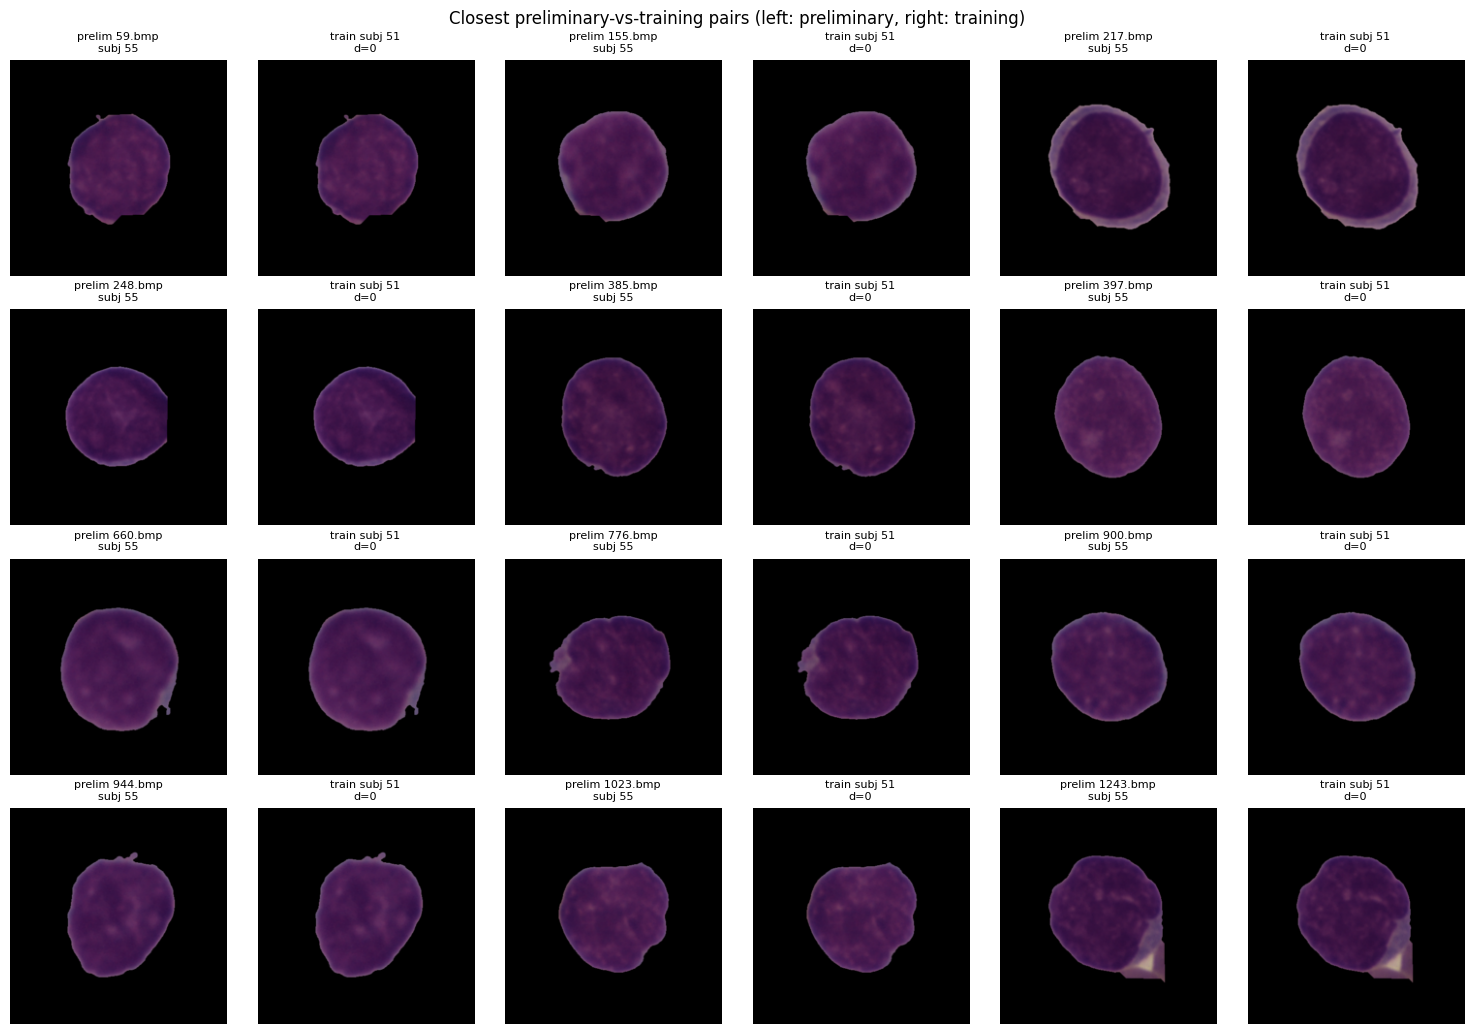

{
  "exact_duplicates_of_training_images": 6,
  "within_cohort_exact_duplicate_files": 0,
  "linked_subject_groups": {},
  "near_duplicate_threshold_bits_of_256": 12,
  "near_duplicate_candidates_vs_training": 41,
  "near_duplicate_candidate_pairs_across_cohort_subjects": 0,
  "nearest_training_distance_quantiles": {
    "0": 0.0,
    "0.01": 2.0,
    "0.05": 54.0,
    "0.5": 65.0
  },
  "exclusion_rule": "Whole preliminary subject excluded if any image is a pixel-identical copy of a training image (rule fixed before inference).",
  "excluded_subjects": {
    "55": {
      "cells": 47,
      "exact_copies": 6,
      "near_duplicates_le_threshold": 41,
      "matched_training_subjects": [
        "51"
      ]
    }
  },
  "near_duplicates_remaining_after_exclusion": 0
}

Excluded subjects: ['55']
Near-duplicate candidates remaining after exclusion: 0


In [35]:
# 11. Duplicate-link audit: exact pixels and near-duplicate screening, within the cohort and against ALL 10,661 training images
lab['path'] = [str(PRELIM_DIR / n) for n in lab.new_names]
cache_f = AUD / 'hash_cache.json'; cache = read_json(cache_f) if cache_f.exists() else {}
def cached(key, path, fn):
    st = os.stat(path); stamp = [st.st_size, st.st_mtime_ns]; e = cache.get(key)
    if not e or e['stamp'] != stamp: e = {'stamp': stamp, 'v': fn(path)}; cache[key] = e
    return e['v']
print('Hashing preliminary images ...')
lab['sha256_pixels'] = [cached('P:' + n, p, pixel_hash) for n, p in zip(lab.new_names, lab.path)]
pre_dh = np.stack([np.array(cached('PD:' + n, p, lambda q: cell_dhash(q).tolist()), dtype=np.uint8)
                   for n, p in zip(lab.new_names, lab.path)])
atomic_json(cache_f, cache)

print('Hashing training images (parallel; resumes from saved cache) ...', flush=True)
from concurrent.futures import ThreadPoolExecutor, as_completed
keys = ['TD:' + rp for rp in RAW_TRAIN.relative_path]
paths = RAW_TRAIN.path.tolist()
def _job(i):
    st = os.stat(paths[i]); stamp = [st.st_size, st.st_mtime_ns]
    e = cache.get(keys[i])
    if e and e['stamp'] == stamp:
        return i, None
    return i, {'stamp': stamp, 'v': cell_dhash(paths[i]).tolist()}
done, t0 = 0, time.time()
with ThreadPoolExecutor(16) as ex:
    for fut in as_completed([ex.submit(_job, i) for i in range(len(paths))]):
        i, e = fut.result()
        if e is not None:
            cache[keys[i]] = e
        done += 1
        if done % 1000 == 0:
            atomic_json(cache_f, cache)
            print(f'   {done}/{len(paths)} ({time.time() - t0:.0f} s)', flush=True)
atomic_json(cache_f, cache)
tr_dh = np.stack([np.array(cache[k]['v'], dtype=np.uint8) for k in keys])

dup_audit = {}
# (a) exact duplicates against training (any of the 10,661 originals, including excluded copies)
cross_exact = lab[lab.sha256_pixels.isin(set(RAW_TRAIN.sha256_pixels))]
dup_audit['exact_duplicates_of_training_images'] = int(len(cross_exact))
# (b) exact duplicates within the cohort, and the subject links they imply
within = lab[lab.sha256_pixels.duplicated(keep=False)].sort_values('sha256_pixels')
dup_audit['within_cohort_exact_duplicate_files'] = int(len(within))
if len(within): assert within.groupby('sha256_pixels').label.nunique().max() == 1, 'Identical pixels with conflicting labels.'
parent = {s: s for s in sorted(lab.subject.unique())}
def find(s):
    while parent[s] != s: parent[s] = parent[parent[s]]; s = parent[s]
    return s
for _, g in within.groupby('sha256_pixels'):
    ids = sorted(g.subject.unique())
    for o in ids[1:]:
        a, b = find(ids[0]), find(o)
        if a != b: parent[max(a, b)] = min(a, b)
lab['analysis_group_id'] = 'PG_' + lab.subject.map(find)
dup_audit['linked_subject_groups'] = {g: sorted(d.subject.unique().tolist())
                                      for g, d in lab.groupby('analysis_group_id') if d.subject.nunique() > 1}
assert lab.groupby('analysis_group_id').label.nunique().max() == 1, 'A linked group crosses classes.'
# (c) near-duplicate screening (cell-crop dHash)
nearest_d = np.empty(len(lab), int); nearest_j = np.empty(len(lab), int)
for s in range(0, len(lab), 100):
    D = hamming(pre_dh[s:s + 100], tr_dh); nearest_j[s:s + 100] = D.argmin(1); nearest_d[s:s + 100] = D.min(1)
lab['nearest_training_distance'] = nearest_d
lab['nearest_training_image'] = RAW_TRAIN.relative_path.to_numpy()[nearest_j]
lab['nearest_training_subject'] = RAW_TRAIN.patient_id.to_numpy()[nearest_j]
Dw = hamming(pre_dh, pre_dh); np.fill_diagonal(Dw, 9999)
diff_subject = lab.subject.to_numpy()[:, None] != lab.subject.to_numpy()[None, :]
wi, wj = np.where(np.triu((Dw <= NEAR_DUP_BITS) & diff_subject, 1))
flag_train = lab[lab.nearest_training_distance <= NEAR_DUP_BITS]
dup_audit['near_duplicate_threshold_bits_of_256'] = NEAR_DUP_BITS
dup_audit['near_duplicate_candidates_vs_training'] = int(len(flag_train))
dup_audit['near_duplicate_candidate_pairs_across_cohort_subjects'] = int(len(wi))
dup_audit['nearest_training_distance_quantiles'] = {q: float(np.quantile(nearest_d, q)) for q in [0, .01, .05, .5]}
atomic_csv(AUD / 'near_duplicates_vs_training.csv', lab.sort_values('nearest_training_distance')
           [['new_names', 'Patient_ID', 'subject', 'label', 'nearest_training_distance',
             'nearest_training_image', 'nearest_training_subject']])
atomic_csv(AUD / 'near_duplicates_within_cohort.csv',
           pd.DataFrame({'a': lab.new_names.to_numpy()[wi], 'b': lab.new_names.to_numpy()[wj],
                         'subject_a': lab.subject.to_numpy()[wi], 'subject_b': lab.subject.to_numpy()[wj],
                         'distance': Dw[wi, wj]}))
# Contact sheet: the 12 closest preliminary-vs-training pairs
top = lab.nsmallest(12, 'nearest_training_distance'); tpath = dict(zip(RAW_TRAIN.relative_path, RAW_TRAIN.path))
fig, axes = plt.subplots(4, 6, figsize=(15, 10.5))
for i, (_, r) in enumerate(top.iterrows()):
    for j, (pth, ttl) in enumerate([(r.path, f'prelim {r.new_names}\nsubj {r.subject}'),
                                    (tpath[r.nearest_training_image],
                                     f'train subj {r.nearest_training_subject}\nd={r.nearest_training_distance}')]):
        ax = axes.flat[2 * i + j]; ax.imshow(_load_image(pth)); ax.set_title(ttl, fontsize=8); ax.axis('off')
fig.suptitle('Closest preliminary-vs-training pairs (left: preliminary, right: training)'); fig.tight_layout()
save_fig(fig, AUD / 'closest_pairs_contact_sheet.png', dpi=150); plt.show(); plt.close(fig)

# (d) Exclusion rule, fixed before any preliminary prediction was made:
#     a preliminary subject with ANY pixel-identical copy of a training image is excluded in full
#     (whole subject), mirroring the linked analysis groups of the primary run.
EXCLUDED_SUBJECTS = sorted(set(cross_exact.subject))
keep_mask = ~lab.subject.isin(EXCLUDED_SUBJECTS).to_numpy()
dist = lab.nearest_training_distance.to_numpy()
NEAR_FLAGGED = int((dist[keep_mask] <= NEAR_DUP_BITS).sum()) + int((keep_mask[wi] & keep_mask[wj]).sum())
dup_audit['exclusion_rule'] = ('Whole preliminary subject excluded if any image is a pixel-identical '
                               'copy of a training image (rule fixed before inference).')
dup_audit['excluded_subjects'] = {
    s: {'cells': int((lab.subject == s).sum()),
        'exact_copies': int((cross_exact.subject == s).sum()),
        'near_duplicates_le_threshold': int(((lab.subject == s).to_numpy() & (dist <= NEAR_DUP_BITS)).sum()),
        'matched_training_subjects': sorted(set(lab.loc[(lab.subject == s) &
                                                        (lab.nearest_training_distance <= NEAR_DUP_BITS),
                                                        'nearest_training_subject']))}
    for s in EXCLUDED_SUBJECTS}
dup_audit['near_duplicates_remaining_after_exclusion'] = NEAR_FLAGGED
atomic_json(AUD / 'duplicate_audit.json', dup_audit)
print(json.dumps(dup_audit, indent=2))
print('\nExcluded subjects:', EXCLUDED_SUBJECTS)
print('Near-duplicate candidates remaining after exclusion:', NEAR_FLAGGED)

A. EXACT duplicates of training images:


,new_names,Patient_ID,subject,label,train_files,train_subjects,train_labels
0,59.bmp,UID_55_12_2_all.bmp,55,1,[fold_1/all/UID_51_59_2_all.bmp],[51],[1]
1,385.bmp,UID_55_15_1_all.bmp,55,1,[fold_1/all/UID_51_74_1_all.bmp],[51],[1]
2,660.bmp,UID_55_10_2_all.bmp,55,1,[fold_1/all/UID_51_49_3_all.bmp],[51],[1]
3,944.bmp,UID_55_10_1_all.bmp,55,1,[fold_1/all/UID_51_49_1_all.bmp],[51],[1]
4,1023.bmp,UID_55_12_1_all.bmp,55,1,[fold_1/all/UID_51_59_1_all.bmp],[51],[1]
5,1359.bmp,UID_55_27_2_all.bmp,55,1,[fold_1/all/UID_51_134_2_all.bmp],[51],[1]



B. Near-duplicates (<= 12 bits), by preliminary subject and matched training subject:


,subject,label,nearest_training_subject,flagged_cells,min_d,max_d,train_label,subject_total_cells
0,55,1,51,41,0,12,1,47



C. Distance distribution of flagged images:
{0: 18, 2: 3, 3: 3, 4: 3, 5: 1, 7: 3, 8: 2, 9: 2, 10: 2, 11: 2, 12: 2}

D. Calibration within training (800 sampled images):
{
  "nearest_other_subject": {
    "0": 0.0,
    "0.001": 0.0,
    "0.01": 0.0,
    "0.05": 8.0,
    "0.5": 62.0
  },
  "nearest_same_subject": {
    "0": 0.0,
    "0.001": 0.0,
    "0.01": 1.0,
    "0.05": 13.0,
    "0.5": 72.0
  },
  "other_subject_pairs_le_threshold_pct": 6.5
}


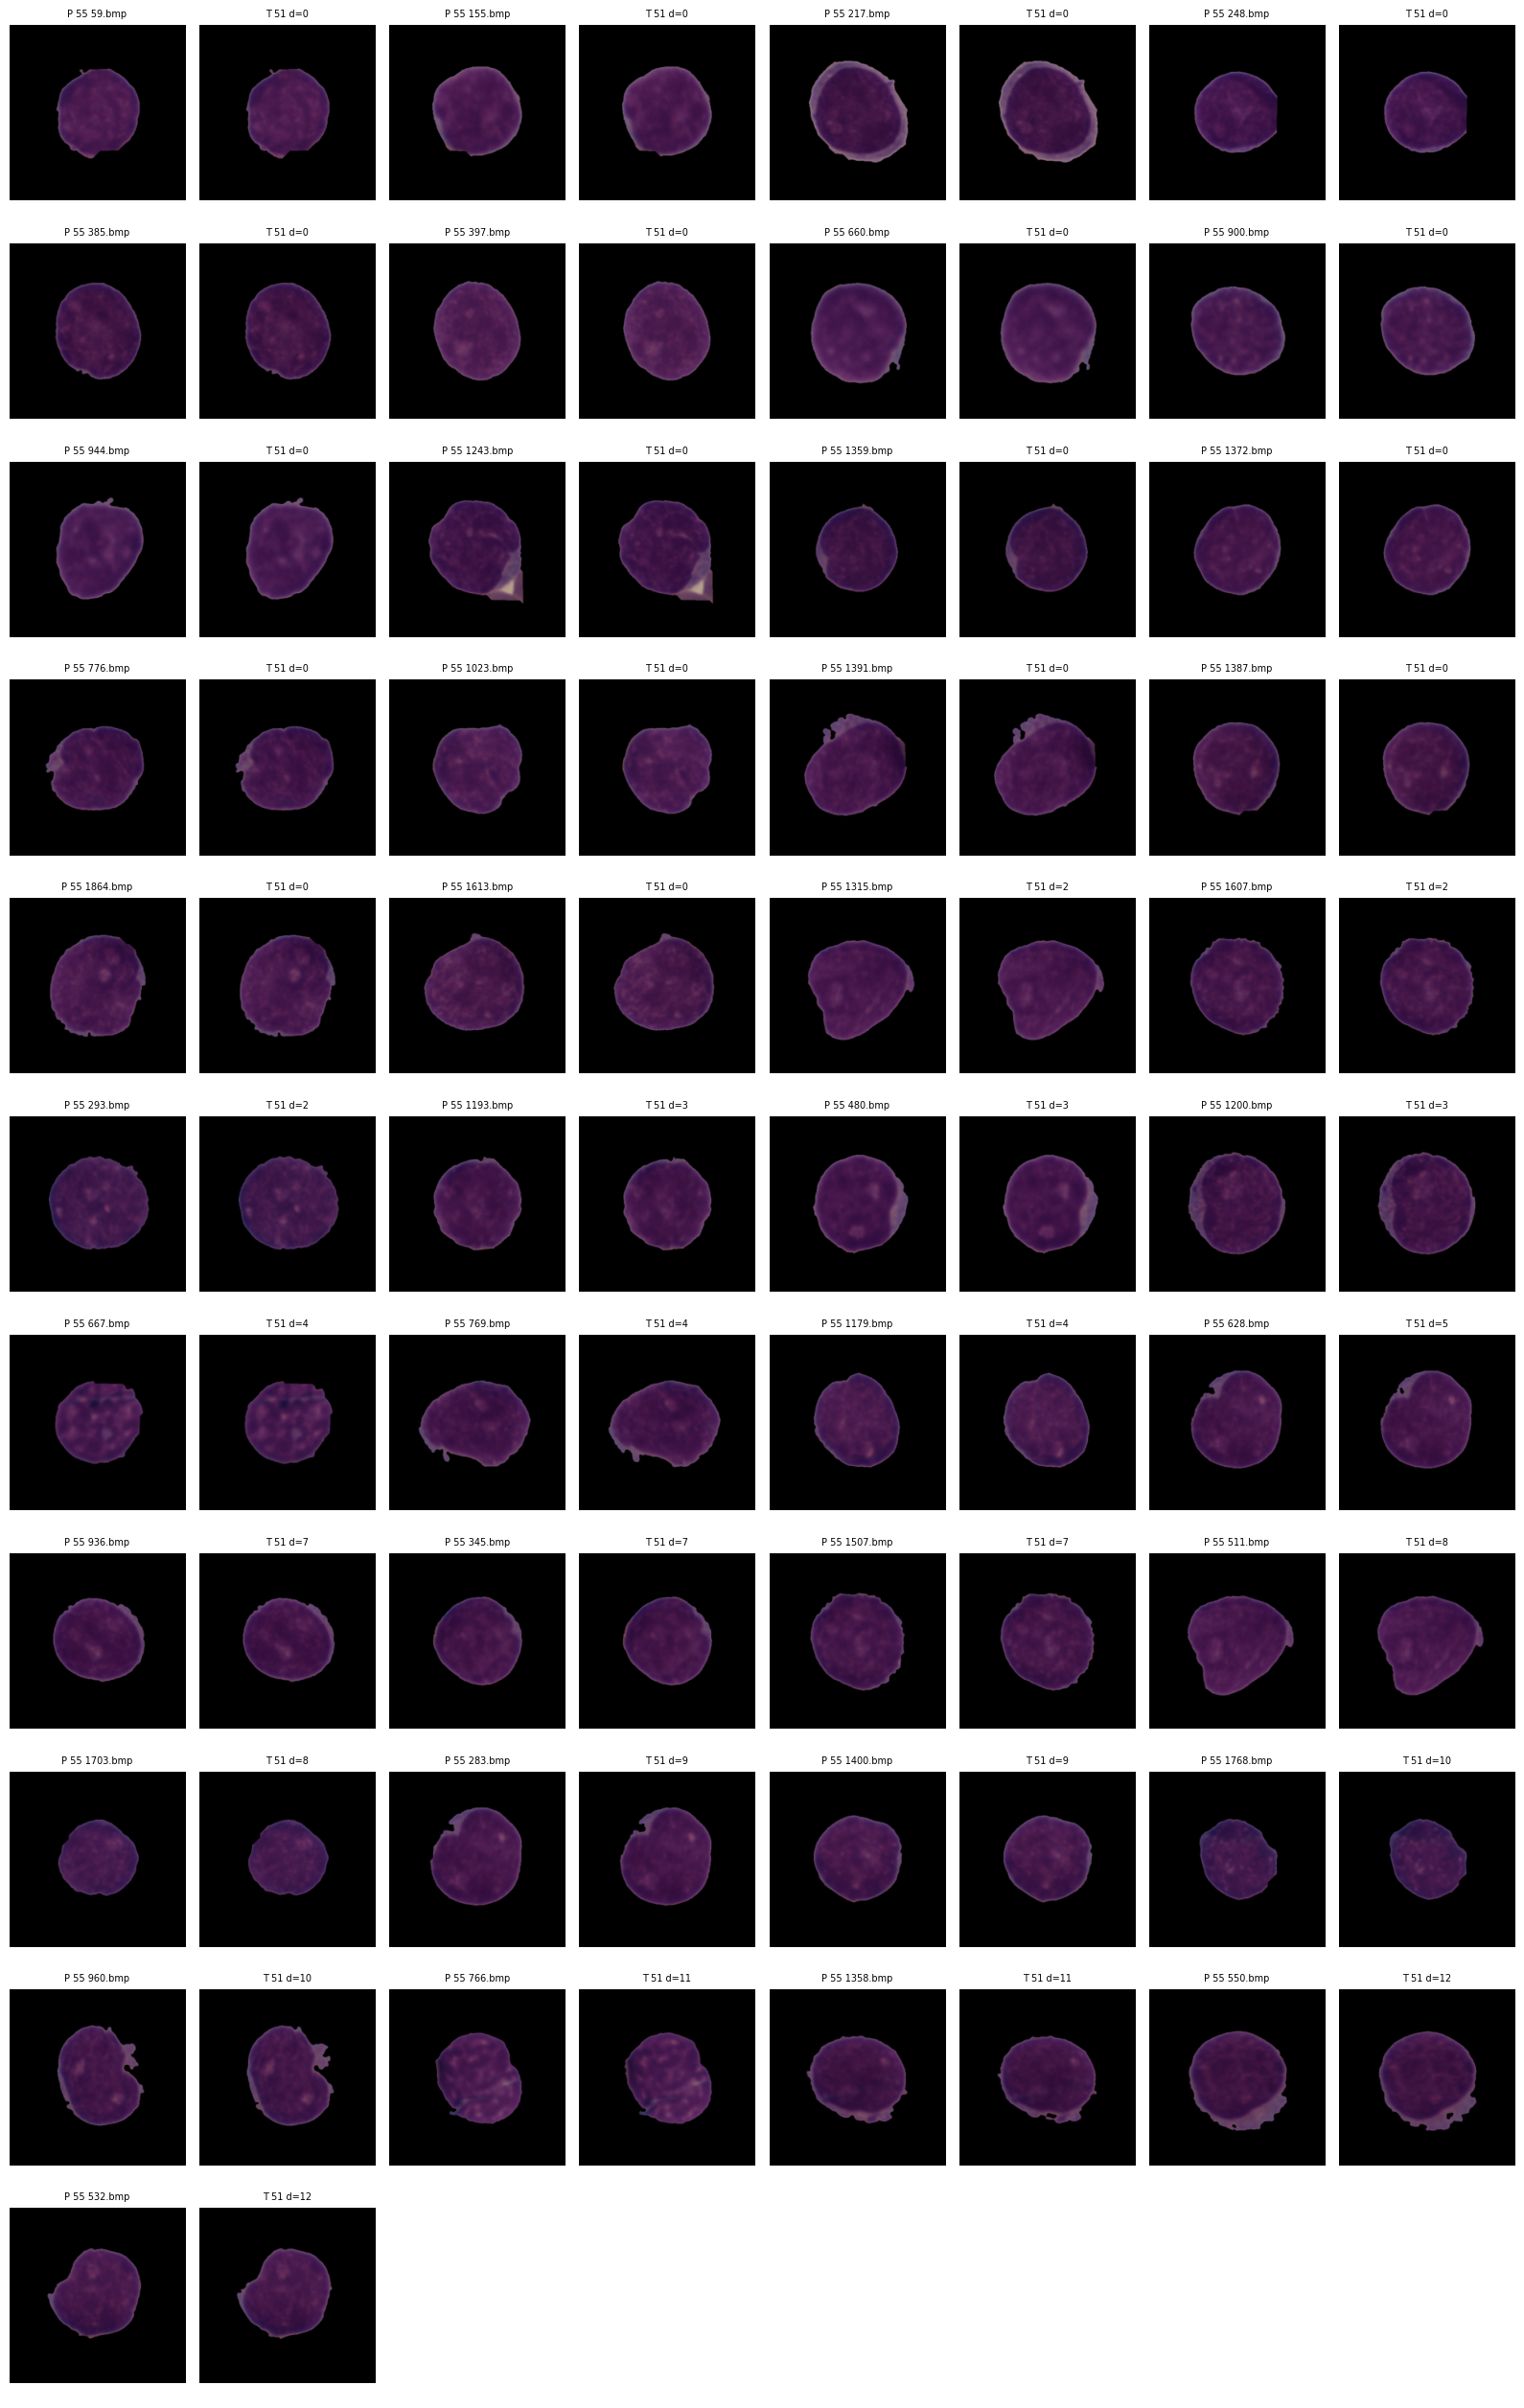

Saved. Subjects implicated: ['55']


In [19]:
# 11b. Which preliminary subjects share images with training? (read-only)
tr_by_hash = (RAW_TRAIN.groupby('sha256_pixels')
              .agg(train_files=('relative_path', lambda s: sorted(s)),
                   train_subjects=('patient_id', lambda s: sorted(set(s))),
                   train_labels=('label', lambda s: sorted(set(s))))
              .reset_index())
ex = lab.merge(tr_by_hash, on='sha256_pixels', how='inner')
print('A. EXACT duplicates of training images:')
display(ex[['new_names', 'Patient_ID', 'subject', 'label',
            'train_files', 'train_subjects', 'train_labels']])

near = lab[lab.nearest_training_distance <= NEAR_DUP_BITS].copy()
tl = RAW_TRAIN.set_index('relative_path').label
near['train_label'] = tl.loc[near.nearest_training_image].to_numpy()
cells = lab.groupby('subject').size()
by_subj = (near.groupby(['subject', 'label', 'nearest_training_subject'])
           .agg(flagged_cells=('new_names', 'size'),
                min_d=('nearest_training_distance', 'min'),
                max_d=('nearest_training_distance', 'max'),
                train_label=('train_label', 'first'))
           .reset_index())
by_subj['subject_total_cells'] = by_subj.subject.map(cells)
print('\nB. Near-duplicates (<= %d bits), by preliminary subject and matched training subject:' % NEAR_DUP_BITS)
display(by_subj)
print('\nC. Distance distribution of flagged images:')
print(near.nearest_training_distance.value_counts().sort_index().to_dict())

# D. Calibration: how close are DIFFERENT training subjects' images to each other?
rng = np.random.default_rng(0)
smp = rng.choice(len(RAW_TRAIN), 800, replace=False)
tsub = RAW_TRAIN.patient_id.str.upper().to_numpy()
thash = RAW_TRAIN.sha256_pixels.to_numpy()
other, same = [], []
for s in range(0, len(smp), 100):
    ii = smp[s:s + 100]; D = hamming(tr_dh[ii], tr_dh)
    for k, i in enumerate(ii):
        dist = D[k].astype(float); dist[thash == thash[i]] = np.inf   # ignore itself / exact copies
        o = dist.copy(); o[tsub == tsub[i]] = np.inf; other.append(o.min())
        sm = dist.copy(); sm[tsub != tsub[i]] = np.inf; same.append(sm.min())
calib = {'nearest_other_subject': {q: float(np.quantile(other, q)) for q in [0, .001, .01, .05, .5]},
         'nearest_same_subject':  {q: float(np.quantile(same, q)) for q in [0, .001, .01, .05, .5]},
         'other_subject_pairs_le_threshold_pct': float(np.mean(np.array(other) <= NEAR_DUP_BITS) * 100)}
print('\nD. Calibration within training (800 sampled images):'); print(json.dumps(calib, indent=2))

# E. Contact sheet of every flagged pair (left: preliminary, right: training)
fl = near.sort_values('nearest_training_distance').reset_index(drop=True)
tpath = dict(zip(RAW_TRAIN.relative_path, RAW_TRAIN.path))
n = len(fl); rows_ = int(np.ceil(n / 4))
fig, axes = plt.subplots(rows_, 8, figsize=(16, 2.3 * rows_))
for ax in axes.flat: ax.axis('off')
for i, r in fl.iterrows():
    for j, (pth, ttl) in enumerate([(r.path, f'P {r.subject} {r.new_names}'),
                                    (tpath[r.nearest_training_image],
                                     f'T {r.nearest_training_subject} d={r.nearest_training_distance}')]):
        ax = axes.flat[2 * i + j]; ax.imshow(_load_image(pth)); ax.set_title(ttl, fontsize=7)
fig.tight_layout(); save_fig(fig, AUD / 'flagged_pairs_contact_sheet.png', dpi=110)
plt.show(); plt.close(fig)

atomic_csv(AUD / 'exact_duplicates_vs_training.csv', ex.drop(columns=['path']))
atomic_csv(AUD / 'near_duplicates_by_subject.csv', by_subj)
atomic_json(AUD / 'near_duplicate_calibration.json', calib)
print('Saved. Subjects implicated:', sorted(set(ex.subject) | set(near.subject)))

In [36]:
# 12. Cohort manifest (after the pre-specified exclusion) and provenance record
# --- retained cohort ---
keep = lab[~lab.new_names.isin({Path(x).name for x in EXCLUDE_CONFIRMED_NEAR_DUPLICATES})
           & ~lab.subject.isin(EXCLUDED_SUBJECTS)].copy()
keep = keep.sort_values('new_names').drop_duplicates('sha256_pixels', keep='first')
PRELIM = pd.DataFrame({'relative_path': 'prelim/' + keep.new_names, 'path': keep.path, 'label': keep.label,
                       'patient_id': keep.analysis_group_id, 'original_patient_id': keep.subject,
                       'original_file_name': keep.Patient_ID, 'sha256_pixels': keep.sha256_pixels}
                      ).sort_values('relative_path').reset_index(drop=True)
removed = {'excluded_subjects': EXCLUDED_SUBJECTS,
           'images_in_excluded_subjects': int(lab.subject.isin(EXCLUDED_SUBJECTS).sum()),
           'exact_within_cohort_copies': int(len(lab) - len(lab.drop_duplicates('sha256_pixels'))),
           'confirmed_near_duplicates_excluded': sorted(EXCLUDE_CONFIRMED_NEAR_DUPLICATES)}
retained = {'images': int(len(PRELIM)),
            'images_by_class': {'ALL': int((PRELIM.label == 1).sum()), 'HEM': int((PRELIM.label == 0).sum())},
            'analysis_groups': int(PRELIM.patient_id.nunique()),
            'groups_by_class': {'ALL': int(PRELIM[PRELIM.label == 1].patient_id.nunique()),
                                'HEM': int(PRELIM[PRELIM.label == 0].patient_id.nunique())}}

# --- safety checks on the retained cohort ---
kept_rows = lab.new_names.isin(keep.new_names)
assert not PRELIM.sha256_pixels.isin(set(RAW_TRAIN.sha256_pixels)).any(), 'A retained image copies a training image.'
assert (lab.loc[kept_rows, 'nearest_training_distance'] > NEAR_DUP_BITS).all(), 'A retained image is a near-duplicate.'
assert not set(PRELIM.original_patient_id) & set(EXCLUDED_SUBJECTS)
assert set(PRELIM.label) == {0, 1}

# --- provenance (records the retained cohort and the exclusion) ---
img_props = []
for p in PRELIM.path.sample(min(200, len(PRELIM)), random_state=0):
    with Image.open(p) as im: img_props.append((im.format, im.mode, im.size))
provenance = {
    'dataset': 'C-NMC 2019 (ISBI 2019 challenge), labelled preliminary-test phase',
    'documented_source': 'The Cancer Imaging Archive, DOI 10.7937/tcia.2019.dc64i46r',
    'documented_composition': DOCUMENTED,
    'local_copy_description': PRELIM_SOURCE_DESCRIPTION or 'NOT YET RECORDED',
    'retrieved_on': PRELIM_RETRIEVED_ON or 'NOT YET RECORDED',
    'label_file': str(PRELIM_LABELS), 'label_file_sha256': sha_file(PRELIM_LABELS),
    'image_folder': str(PRELIM_DIR), 'image_files_listed': int(len(lab)),
    'pixel_hash_list_sha256_all_listed': digest(sorted(lab.sha256_pixels)),
    'pixel_hash_list_sha256_retained': digest(sorted(PRELIM.sha256_pixels)),
    'removed': removed, 'retained': retained,
    'image_properties_sample_200': pd.Series([str(t) for t in img_props]).value_counts().to_dict(),
    'training_image_properties': {f'{w}x{h}': int(n) for (w, h), n in RAW_TRAIN[['width', 'height']].value_counts().items()},
    'relationship_to_training': ('Same centre, staining protocol and acquisition as the training cohort. '
                                 'Subject IDs disjoint from training; one subject excluded for sharing images with a '
                                 'training subject. Not an acquisition-external cohort (does not address Reviewer 2 Q5).'),
    'audits': {'labels': read_json(AUD / 'label_audit.json'), 'identities': read_json(AUD / 'identity_audit.json'),
               'duplicates': read_json(AUD / 'duplicate_audit.json')},
    'count_mismatch_reason': ACCEPT_COUNT_MISMATCH_REASON or None,
    'provenance_confirmed': bool(PRELIM_PROVENANCE_CONFIRMED), 'time': now()}
atomic_json(AUD / 'provenance.json', provenance)

print(json.dumps({k: v for k, v in provenance.items() if k != 'audits'}, indent=2))
print('\nRetained:', retained)
if not (PRELIM_PROVENANCE_CONFIRMED and PRELIM_SOURCE_DESCRIPTION and PRELIM_RETRIEVED_ON):
    print('\nNEXT: fill PRELIM_SOURCE_DESCRIPTION and PRELIM_RETRIEVED_ON, set PRELIM_PROVENANCE_CONFIRMED = True '
          'in cell 2, rerun cell 2, then RERUN THIS CELL (so the record is complete), then run cell 13.')
else:
    print('\nProvenance recorded and confirmed. You can run cell 13.')

{
  "dataset": "C-NMC 2019 (ISBI 2019 challenge), labelled preliminary-test phase",
  "documented_source": "The Cancer Imaging Archive, DOI 10.7937/tcia.2019.dc64i46r",
  "documented_composition": {
    "images": 1867,
    "images_ALL": 1219,
    "images_HEM": 648,
    "subjects": 28,
    "subjects_ALL": 13,
    "subjects_HEM": 15
  },
  "local_copy_description": "Kaggle mirror of the TCIA C-NMC 2019 release (\"Leukemia Classification\"), downloaded by the authors",
  "retrieved_on": "2026-05",
  "label_file": "/content/drive/MyDrive/leukemia_4model_run/data/raw/C-NMC_Leukemia/validation_data/C-NMC_test_prelim_phase_data_labels.csv",
  "label_file_sha256": "3f5d770a51017f242db857e178de5341f294e38fff82c266a1a8d292c9fc3d0d",
  "image_folder": "/content/drive/MyDrive/leukemia_4model_run/data/raw/C-NMC_Leukemia/validation_data/C-NMC_test_prelim_phase_data",
  "image_files_listed": 1867,
  "pixel_hash_list_sha256_all_listed": "7da58bac6b51c66f374b5d122b4d100e795bd0dbea75462d46bf6f9feb3ef2eb

  scanned 0/10661 images (0 s)
  scanned 2000/10661 images (1 s)
  scanned 4000/10661 images (3 s)
  scanned 6000/10661 images (4 s)
  scanned 8000/10661 images (6 s)
  scanned 10000/10661 images (7 s)

Cross-subject near-duplicate pairs (<= 12 of 256 bits, not exact copies): 337
  within the same analysis group     : 305
  different groups, same partition   : 14
  ACROSS PARTITIONS                  : 18
  across partitions, by partition pair: {'test vs train': 17, 'train vs validation': 1}
  distance distribution (all pairs): {0: 94, 1: 36, 2: 27, 3: 28, 4: 20, 5: 18, 6: 27, 7: 20, 8: 14, 9: 13, 10: 16, 11: 12, 12: 12}

B1. Subject pairs with the most near-duplicate images (top 25):


,subject_a,subject_b,group_a,group_b,partition_a,partition_b,label_a,label_b,pairs,min_d,n_d0,cells_a,cells_b,cross_partition
8,51,78,LG_51,LG_51,train,train,1,1,161,0,37,757,218,False
7,51,75,LG_51,LG_51,train,train,1,1,66,0,24,757,99,False
9,H10,h3,LG_H10,LG_H10,train,train,0,0,29,0,15,405,36,False
12,H2,H5,LG_H2,LG_H2,train,train,0,0,23,0,6,112,28,False
13,H6,H2,LG_H2,LG_H2,train,train,0,0,18,0,5,18,112,False
15,H7,H2,LG_H7,LG_H2,test,train,0,0,17,0,4,18,112,True
1,17,18,LG_17,LG_18,train,train,1,1,7,9,0,74,74,False
11,H2,H4,LG_H2,LG_H2,train,train,0,0,6,0,3,112,9,False
10,H19,H20,LG_H19,LG_H20,train,train,0,0,2,5,0,108,100,False
14,H6,H5,LG_H2,LG_H2,train,train,0,0,2,8,0,18,28,False



B2. Subject pairs linked ACROSS partitions:


,subject_a,subject_b,group_a,group_b,partition_a,partition_b,label_a,label_b,pairs,min_d,n_d0,cells_a,cells_b,cross_partition
15,H7,H2,LG_H7,LG_H2,test,train,0,0,17,0,4,18,112,True
5,43,44,LG_43,LG_44,train,validation,1,1,1,9,0,73,146,True



C. Saved primary test predictions with test groups linked to train/validation removed:


,threshold_bits,excluded_test_groups,name,accuracy,balanced_accuracy,macro_f1,sensitivity_all,specificity_hem,roc_auc,n_images,n_analysis_groups
2,0,LG_H7,DenseNet121__baseline__seed42,0.8644,0.7913,0.8216,0.9896,0.5930,0.9360,1549,9
8,0,LG_H7,MobileNetV2__baseline__seed42,0.8664,0.7972,0.8260,0.9849,0.6094,0.9295,1549,9
17,0,LG_H7,ResNet50__class_weighted__seed42,0.8851,0.8422,0.8595,0.9585,0.7260,0.9182,1549,9
20,0,LG_H7,Xception__baseline__seed42,0.8683,0.8090,0.8331,0.9698,0.6483,0.9304,1549,9
24,0,LG_H7,SoftVote,0.8948,0.8383,0.8662,0.9915,0.6851,0.9504,1549,9
25,0,LG_H7,WeightedVote,0.8954,0.8393,0.8671,0.9915,0.6871,0.9504,1549,9
26,0,LG_H7,Stacked,0.9006,0.8519,0.8759,0.9840,0.7198,0.9494,1549,9
29,4,LG_H7,DenseNet121__baseline__seed42,0.8644,0.7913,0.8216,0.9896,0.5930,0.9360,1549,9
35,4,LG_H7,MobileNetV2__baseline__seed42,0.8664,0.7972,0.8260,0.9849,0.6094,0.9295,1549,9
44,4,LG_H7,ResNet50__class_weighted__seed42,0.8851,0.8422,0.8595,0.9585,0.7260,0.9182,1549,9


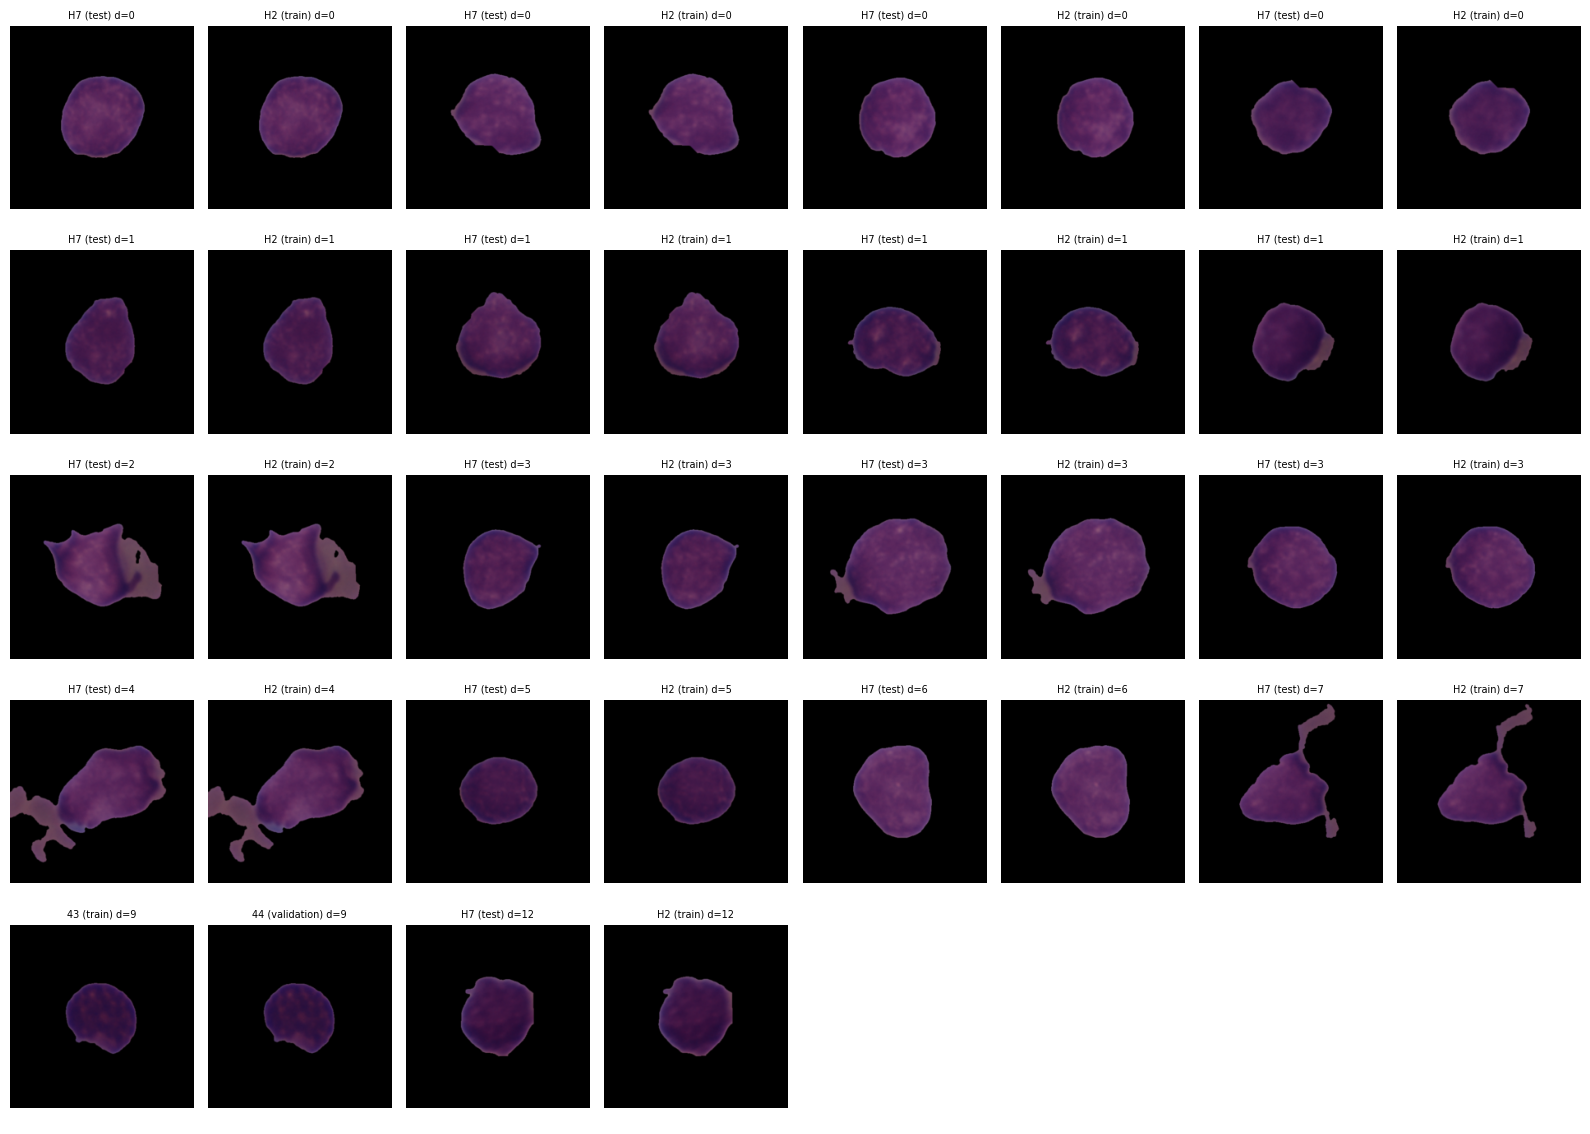


Saved to /content/drive/MyDrive/leukemia_SR_revision_v1_supplementary/primary_partition_audit


In [21]:
# 11c. Read-only audit: do near-duplicate images link subjects ACROSS the primary partitions?
OUTP = SUPP_ROOT / 'primary_partition_audit'
subj = RAW_TRAIN.patient_id.to_numpy()
hsh = RAW_TRAIN.sha256_pixels.to_numpy()
grp_of = (manifest.drop_duplicates('original_patient_id')
          .set_index('original_patient_id').analysis_group_id.to_dict())
part_of = (manifest.drop_duplicates('analysis_group_id')
           .set_index('analysis_group_id').partition.to_dict())
G = np.array([grp_of.get(s, 'UNMAPPED') for s in subj])
PART = np.array([part_of.get(g, 'UNMAPPED') for g in G])
assert (G != 'UNMAPPED').all(), 'Some training subjects have no analysis group - send this output.'

# A. All cross-subject near-duplicate image pairs (exact copies are already linked in the primary run)
pairs, N, t0 = [], len(RAW_TRAIN), time.time()
for s in range(0, N, 100):
    D = hamming(tr_dh[s:s + 100], tr_dh)
    for k in range(D.shape[0]):
        i = s + k
        j = np.flatnonzero(D[k] <= NEAR_DUP_BITS)
        j = j[(j > i) & (subj[j] != subj[i]) & (hsh[j] != hsh[i])]
        pairs += [(i, int(jj), int(D[k, jj])) for jj in j]
    if s % 2000 == 0:
        print(f'  scanned {s}/{N} images ({time.time() - t0:.0f} s)', flush=True)
PR = pd.DataFrame(pairs, columns=['i', 'j', 'distance'])
for side, suf in [('i', 'a'), ('j', 'b')]:
    x = PR[side].to_numpy()
    PR[f'file_{suf}'] = RAW_TRAIN.relative_path.to_numpy()[x]
    PR[f'subject_{suf}'] = subj[x]
    PR[f'group_{suf}'] = G[x]
    PR[f'partition_{suf}'] = PART[x]
    PR[f'label_{suf}'] = RAW_TRAIN.label.to_numpy()[x]
PR['same_group'] = PR.group_a == PR.group_b
PR['cross_partition'] = PR.partition_a != PR.partition_b
atomic_csv(OUTP / 'cross_subject_near_duplicate_pairs.csv', PR.drop(columns=['i', 'j']))

print(f'\nCross-subject near-duplicate pairs (<= {NEAR_DUP_BITS} of 256 bits, not exact copies): {len(PR)}')
print('  within the same analysis group     :', int(PR.same_group.sum()))
print('  different groups, same partition   :', int((~PR.same_group & ~PR.cross_partition).sum()))
print('  ACROSS PARTITIONS                  :', int(PR.cross_partition.sum()))
if len(PR):
    print('  across partitions, by partition pair:',
          PR[PR.cross_partition].apply(lambda r: ' vs '.join(sorted([r.partition_a, r.partition_b])), axis=1)
          .value_counts().to_dict() if PR.cross_partition.any() else {})
    print('  distance distribution (all pairs):', PR.distance.value_counts().sort_index().to_dict())

# B. Summary by subject pair
if len(PR):
    summ = (PR.groupby(['subject_a', 'subject_b', 'group_a', 'group_b',
                        'partition_a', 'partition_b', 'label_a', 'label_b'])
            .agg(pairs=('distance', 'size'), min_d=('distance', 'min'),
                 n_d0=('distance', lambda d: int((d == 0).sum())))
            .reset_index().sort_values('pairs', ascending=False))
    cells = RAW_TRAIN.groupby('patient_id').size()
    summ['cells_a'] = summ.subject_a.map(cells); summ['cells_b'] = summ.subject_b.map(cells)
    summ['cross_partition'] = summ.partition_a != summ.partition_b
    atomic_csv(OUTP / 'by_subject_pair.csv', summ)
    print('\nB1. Subject pairs with the most near-duplicate images (top 25):')
    display(summ.head(25))
    print('\nB2. Subject pairs linked ACROSS partitions:')
    display(summ[summ.cross_partition])
else:
    summ = pd.DataFrame()
    print('\nNo cross-subject near-duplicate pairs found.')

# C. Sensitivity: rescore the SAVED primary test predictions without linked test groups (no retraining)
fin = PRIMARY_ROOT / 'final_test'
names = pd.read_csv(fin / 'all_metrics.csv').name.tolist()
cp = PR[PR.cross_partition & ((PR.partition_a == 'test') | (PR.partition_b == 'test'))] if len(PR) else PR
rows = []
for thr in [0, 4, NEAR_DUP_BITS]:
    c = cp[cp.distance <= thr] if len(cp) else cp
    excl = sorted(set(c.loc[c.partition_a == 'test', 'group_a']) | set(c.loc[c.partition_b == 'test', 'group_b'])) if len(c) else []
    for n in names:
        p = load_pred(fin / f'{n}_predictions.csv')
        kept = p[~p.patient_id.isin(excl)]
        if kept.label.nunique() < 2:
            continue
        m = metrics(kept)
        rows.append({'threshold_bits': thr, 'excluded_test_groups': ', '.join(excl) or 'none', 'name': n,
                     **{k: m[k] for k in ['accuracy', 'balanced_accuracy', 'macro_f1', 'sensitivity_all',
                                          'specificity_hem', 'roc_auc', 'n_images', 'n_analysis_groups']}})
SENS = pd.DataFrame(rows)
atomic_csv(OUTP / 'sensitivity_rescoring.csv', SENS)
print('\nC. Saved primary test predictions with test groups linked to train/validation removed:')
display(SENS[SENS.name.isin(BASE_NAMES + ['SoftVote', 'WeightedVote', 'Stacked'])].round(4))

# D. Contact sheet of cross-partition pairs (closest first, up to 24)
cx = PR[PR.cross_partition].sort_values('distance').head(24).reset_index(drop=True) if len(PR) else PR
if len(cx):
    tpath = dict(zip(RAW_TRAIN.relative_path, RAW_TRAIN.path))
    rr = int(np.ceil(len(cx) / 4))
    fig, axes = plt.subplots(rr, 8, figsize=(16, 2.3 * rr), squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for i, r in cx.iterrows():
        for j, (f, s, pt) in enumerate([(r.file_a, r.subject_a, r.partition_a),
                                        (r.file_b, r.subject_b, r.partition_b)]):
            ax = axes.ravel()[2 * i + j]
            ax.imshow(_load_image(tpath[f])); ax.set_title(f'{s} ({pt}) d={r.distance}', fontsize=7)
    fig.tight_layout(); save_fig(fig, OUTP / 'cross_partition_pairs.png', dpi=110)
    plt.show(); plt.close(fig)
else:
    print('\nD. No cross-partition pairs to show.')
print('\nSaved to', OUTP)

## Preliminary-test cohort: frozen-model inference

Every completed primary run (24) and the three frozen ensembles are applied without change: the same checkpoints, the meta-learner fitted on out-of-fold training predictions, and the 0.5 threshold. Uncertainty resamples whole analysis groups within class, and the 13 prespecified comparisons are Holm-adjusted as one family.

In [ ]:
# 13. Confirmation gate, manifest lock, inference (with pre-flight checks and progress)

# --- gate ---
assert PRELIM_PROVENANCE_CONFIRMED, 'Set PRELIM_PROVENANCE_CONFIRMED = True in cell 2 and rerun cell 2.'
assert PRELIM_SOURCE_DESCRIPTION and PRELIM_RETRIEVED_ON, 'Record source and date in cell 2.'
assert NEAR_FLAGGED == 0 or NEAR_DUPLICATES_REVIEWED, 'Review near-duplicate candidates first.'

# --- pre-flight checks ---
prov = read_json(AUD / 'provenance.json')
ok_prov = prov.get('provenance_confirmed')
ok_desc = prov.get('local_copy_description') == PRELIM_SOURCE_DESCRIPTION
assert ok_prov and ok_desc, 'Rerun cell 12 after confirming in cell 2.'

excluded_left = set(PRELIM.original_patient_id) & set(EXCLUDED_SUBJECTS)
assert not excluded_left, 'Excluded subjects are still in the cohort - rerun cell 12.'

_t = PRELIM.path.iloc[0]
_im = Image.open(_t).convert('RGB')
_ref = np.asarray(_im.resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR))
assert np.array_equal(_load_image(_t), _ref), 'Cell 5 must use Image.BILINEAR.'

tf.config.experimental.enable_tensor_float_32_execution(True)
assert tf.config.experimental.tensor_float_32_execution_enabled()

gpu_name = tf.config.experimental.get_device_details(GPUS[0]).get('device_name', 'GPU')
n_all = PRELIM[PRELIM.label == 1].patient_id.nunique()
n_hem = PRELIM[PRELIM.label == 0].patient_id.nunique()
print(f'Cohort: {len(PRELIM)} images | {PRELIM.patient_id.nunique()} groups '
      f'(ALL {n_all}, HEM {n_hem}) | excluded: {EXCLUDED_SUBJECTS} '
      f'| GPU: {gpu_name} | TF32 on | resize: BILINEAR', flush=True)

# --- lock (written once; later runs must match) ---
lock_f = PRELIM_OUT / 'manifest_lock.json'
cols = ['relative_path', 'label', 'patient_id', 'sha256_pixels']
mh = digest(PRELIM[cols].values.tolist())
settings = {'gpu': gpu_name, 'tf32': True, 'resize': 'PIL BILINEAR',
            'tensorflow': tf.__version__, 'threshold': 0.5}
lock = {'manifest_hash': mh,
        'primary_fingerprint': PRIMARY_FINGERPRINT,
        'source': PRELIM_SOURCE_DESCRIPTION,
        'retrieved_on': PRELIM_RETRIEVED_ON,
        'near_duplicates_reviewed': bool(NEAR_DUPLICATES_REVIEWED),
        'excluded_subjects': EXCLUDED_SUBJECTS,
        'n_images': int(len(PRELIM)),
        'inference_settings': settings}
if lock_f.exists():
    old = read_json(lock_f)
    same = (old['manifest_hash'] == mh and
            old['primary_fingerprint'] == PRIMARY_FINGERPRINT)
    assert same, 'Manifest or primary files changed since the lock - investigate.'
    print('Existing lock verified.', flush=True)
else:
    atomic_json(lock_f, {**lock, 'confirmed_at': now()})
    atomic_csv(PRELIM_OUT / 'manifest.csv', PRELIM)
    print('Manifest locked.', flush=True)

# --- inference: all 24 frozen primary runs ---
EVB = PRELIM_OUT / 'evaluation'
print('Reading preliminary images ...', flush=True)
x_pre = image_array(PRELIM.path.tolist(), 'prelim')
PB, recs = {}, []
t0 = time.time()
for k, path in enumerate(MAIN_RUNS, 1):
    r = read_json(path)
    key = run_key(r)
    dest = EVB / f'{key}_predictions.csv'
    if dest.exists():
        pred = load_pred(dest)
        note = 'reused saved predictions'
    else:
        m = load_frozen(r['best_model'])
        pred = prediction_frame(PRELIM, predict_array(m, x_pre))
        del m
        tf.keras.backend.clear_session()
        gc.collect()
        note = 'predicted'
    PB[key] = pred
    met = save_eval(key, pred, EVB)
    recs.append({'name': key, 'model': r['model'], 'strategy': r['strategy'],
                 'seed': r['seed'], **met})
    print(f'  [{k:2d}/{len(MAIN_RUNS)}] {key}: {note} '
          f'| accuracy {met["accuracy"]:.4f} '
          f'| specificity {met["specificity_hem"]:.4f} '
          f'({time.time() - t0:.0f} s)', flush=True)

# --- frozen ensembles (seed-42 selected arms, primary meta-learner, threshold 0.5) ---
base = [PB[n].sort_values('relative_path').reset_index(drop=True) for n in BASE_NAMES]
for b in base[1:]:
    assert b.relative_path.equals(base[0].relative_path)
X = np.column_stack([b.p_all for b in base])
for ename, p in ensemble_probs(X).items():
    z = base[0].copy()
    z['p_all'] = p
    z['prediction'] = (p >= .5).astype(int)
    PB[ename] = z
    met = save_eval(ename, z, EVB)
    recs.append({'name': ename, 'model': ename, 'strategy': 'ensemble',
                 'seed': SEEDS[0], **met})

B_METRICS = pd.DataFrame(recs)
atomic_csv(EVB / 'all_metrics.csv', B_METRICS)
show = ['name', 'accuracy', 'balanced_accuracy', 'macro_f1',
        'sensitivity_all', 'specificity_hem', 'roc_auc']
display(B_METRICS[show].round(4))
print('Cell 13 complete.')

Cohort: 1820 images | 27 groups (ALL 12, HEM 15) | excluded: ['55'] | GPU: NVIDIA L4 | TF32 on | resize: BILINEAR
Manifest locked.
Reading preliminary images ...
  prelim: 200/1820 images read (2 s)
  prelim: 400/1820 images read (3 s)
  prelim: 600/1820 images read (4 s)
  prelim: 800/1820 images read (5 s)
  prelim: 1000/1820 images read (6 s)
  prelim: 1200/1820 images read (6 s)
  prelim: 1400/1820 images read (7 s)
  prelim: 1600/1820 images read (9 s)
  prelim: 1800/1820 images read (9 s)
  prelim: 1820/1820 images read (10 s)
  copied checkpoint (34 MB) in 3 s
  [ 1/24] DenseNet121__baseline__seed123: predicted | accuracy 0.6791 | specificity 0.1651 (19 s)
  copied checkpoint (34 MB) in 2 s
  [ 2/24] DenseNet121__baseline__seed2026: predicted | accuracy 0.6863 | specificity 0.1975 (37 s)
  [ 3/24] DenseNet121__baseline__seed42: predicted | accuracy 0.6725 | specificity 0.1111 (51 s)
  copied checkpoint (34 MB) in 3 s
  [ 4/24] DenseNet121__class_weighted__seed123: predicted | ac

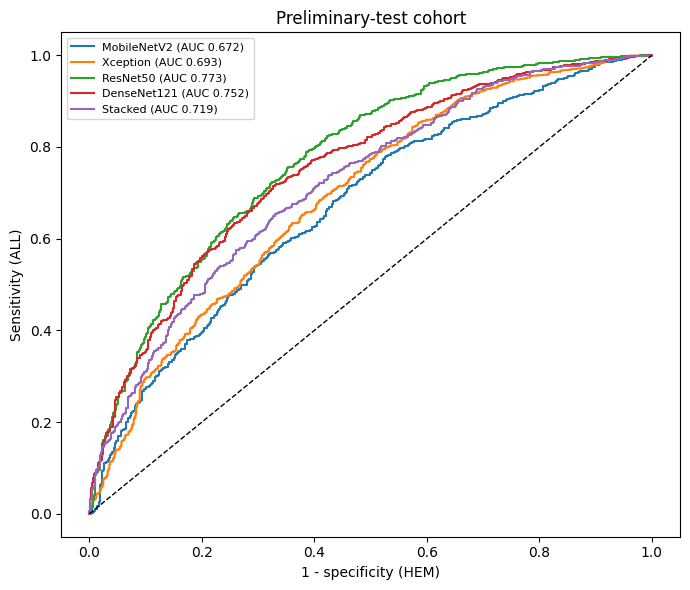

Across seeds:


accuracy         balanced_accuracy          \
                               mean     std              mean     std   
model       strategy                                                    
DenseNet121 baseline         0.6793  0.0069            0.5627  0.0150   
            class_weighted   0.6875  0.0058            0.5847  0.0053   
MobileNetV2 baseline         0.6725  0.0095            0.5537  0.0131   
            class_weighted   0.6892  0.0116            0.5801  0.0154   
ResNet50    baseline         0.7205  0.0268            0.6211  0.0444   
            class_weighted   0.7317  0.0138            0.6381  0.0215   
Xception    baseline         0.6943  0.0019            0.5938  0.0141   
            class_weighted   0.6842  0.0152            0.5728  0.0177   

                           macro_f1         sensitivity_all          \
                               mean     std            mean     std   
model       strategy                                                  
DenseNet121 baseline         0.5264  0.0297          0.9676  0.0137   
            class_weighted   0.5680  0.0094          0.9420  0.0185   
MobileNetV2 baseline         0.5125  0.0243          0.9664  0.0168   
            class_weighted   0.5569  0.0231          0.9590  0.0073   
ResNet50    baseline         0.6106  0.0667          0.9664  0.0179   
            class_weighted   0.6374  0.0288          0.9630  0.0076   
Xception    baseline         0.5790  0.0290          0.9428  0.0361   
            class_weighted   0.5455  0.0261          0.9599  0.0170   

                           specificity_hem         roc_auc          
                                      mean     std    mean     std  
model       strategy                                                
DenseNet121 baseline                0.1579  0.0437  0.7327  0.0185  
            class_weighted          0.2274  0.0232  0.7124  0.0074  
MobileNetV2 baseline                0.1409  0.0340  0.6925  0.0383  
            class_weighted          0.2011  0.0301  0.7093  0.0220  
ResNet50    baseline                0.2757  0.1060  0.8076  0.0188  
            class_weighted          0.3133  0.0488  0.7954  0.0198  
Xception    baseline                0.2449  0.0641  0.6841  0.0084  
            class_weighted          0.1857  0.0327  0.6742  0.0227

Rank comparison (balanced accuracy):


,model,strategy,primary_mean_balanced_accuracy,prelim_mean_balanced_accuracy,primary_rank,prelim_rank
0,DenseNet121,baseline,0.8051,0.5627,5,7
1,DenseNet121,class_weighted,0.8352,0.5847,1,4
2,MobileNetV2,baseline,0.7933,0.5537,7,8
3,MobileNetV2,class_weighted,0.7968,0.5801,6,5
4,ResNet50,baseline,0.8206,0.6211,4,2
5,ResNet50,class_weighted,0.8217,0.6381,3,1
6,Xception,baseline,0.8226,0.5938,2,3
7,Xception,class_weighted,0.7766,0.5728,8,6


In [38]:
# 14. Across-seed summary, per-subject accuracy, rank comparison with the primary test, figures
single = B_METRICS[B_METRICS.strategy != 'ensemble']
KEYS = ['accuracy', 'balanced_accuracy', 'macro_f1', 'sensitivity_all', 'specificity_hem', 'roc_auc']
B_SEED = single.groupby(['model', 'strategy'])[KEYS].agg(['mean', 'std']); B_SEED.to_csv(_guard(EVB / 'across_seed_summary.csv'))
prim = pd.read_csv(PRIMARY_ROOT / 'final_test' / 'all_metrics.csv'); prim_single = prim[prim.strategy != 'ensemble']
rank = pd.DataFrame({
    'primary_mean_balanced_accuracy': prim_single.groupby(['model', 'strategy']).balanced_accuracy.mean(),
    'prelim_mean_balanced_accuracy': single.groupby(['model', 'strategy']).balanced_accuracy.mean()})
rank['primary_rank'] = rank.primary_mean_balanced_accuracy.rank(ascending=False).astype(int)
rank['prelim_rank'] = rank.prelim_mean_balanced_accuracy.rank(ascending=False).astype(int)
rank = rank.reset_index(); atomic_csv(EVB / 'rank_comparison.csv', rank)
rows = []
for n in BASE_NAMES + ['SoftVote', 'WeightedVote', 'Stacked']:
    d = PB[n].assign(ok=lambda x: (x.label == x.prediction).astype(float))
    for (g, y), s in d.groupby(['patient_id', 'label']): rows.append({'run': n, 'analysis_group': g, 'label': y, 'cells': len(s), 'accuracy': s.ok.mean()})
PER_SUBJECT = pd.DataFrame(rows); atomic_csv(EVB / 'per_group_accuracy.csv', PER_SUBJECT)
fig, ax = plt.subplots(figsize=(7, 6))
for n in BASE_NAMES + ['Stacked']:
    p = PB[n]; fpr, tpr, _ = roc_curve(p.label, p.p_all)
    ax.plot(fpr, tpr, label=f"{n.split('__')[0]} (AUC {roc_auc_score(p.label, p.p_all):.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set(xlabel='1 - specificity (HEM)', ylabel='Sensitivity (ALL)', title='Preliminary-test cohort')
ax.legend(fontsize=8); fig.tight_layout(); save_fig(fig, EVB / 'combined_roc.png', dpi=300); plt.show(); plt.close(fig)
print('Across seeds:'); display(B_SEED.round(4)); print('Rank comparison (balanced accuracy):'); display(rank.round(4))

In [ ]:
# 15. Group-level confidence intervals and the 13 prespecified paired comparisons (Holm)
CI_NAMES = [f'{n}__{s}__seed{SEEDS[0]}' for n in MODELS for s in STRATEGIES] + ['SoftVote', 'WeightedVote', 'Stacked']
ci_rows = []
for n in CI_NAMES:
    dest = EVB / 'ci' / f'{n}.json'
    ci = read_json(dest) if dest.exists() else cluster_ci(PB[n]); atomic_json(dest, ci)
    ci_rows.append({'name': n, **{f'{k}': f"{v['estimate']:.4f} [{v['low']:.4f}, {v['high']:.4f}]" for k, v in ci.items()}})
B_CI = pd.DataFrame(ci_rows); atomic_csv(EVB / 'group_bootstrap_ci.csv', B_CI); display(B_CI)
B_PAIRED = run_family(PB, FAMILY, EVB); display(B_PAIRED.round(4))
atomic_json(PRELIM_OUT / 'status.json', {'completed': True, 'time': now(), 'n_images': len(PRELIM),
            'n_groups': int(PRELIM.patient_id.nunique()), 'groups_by_class': {str(k): int(v) for k, v in PRELIM.groupby('label').patient_id.nunique().items()}})
print('Preliminary-cohort evaluation complete.')

## Independent-acquisition dataset for Reviewer 2 Q5 (optional)

The cells below stay off until `EXTERNAL_MANIFEST_CSV` is set. The dataset must come from a **different centre and acquisition** (microscope, camera, staining) and contain **single-cell images labelled as ALL blasts versus non-malignant cells**, compatible with the C-NMC task. Document how its class definitions correspond to C-NMC's before use.

Manifest columns: `path, label (1 = ALL blast, 0 = non-malignant), patient_id (or UNKNOWN), source, site, country, microscope, camera, stain, magnification, label_definition`.

If patient identities are unavailable (`UNKNOWN`), each image is treated as its own resampling unit. Any confidence interval is then image-level and must be reported as such.

Any preprocessing needed to match C-NMC's segmented, black-background crops must be done **before** building the manifest, applied identically to both classes, and described in the manuscript. The models are never re-tuned on this dataset.

In [39]:
# 16. External dataset: audit (runs only when a manifest is supplied)
EXT = None
if not EXTERNAL_MANIFEST_CSV:
    atomic_json(EXTERNAL_OUT / 'status.json', {'completed': False, 'reason': 'No independent-acquisition dataset supplied.', 'time': now()})
    print('No external manifest supplied: Reviewer 2 Q5 is reported as a limitation.')
else:
    need = ['path', 'label', 'patient_id', 'source', 'site', 'country', 'microscope', 'camera', 'stain', 'magnification', 'label_definition']
    ext = pd.read_csv(EXTERNAL_MANIFEST_CSV, dtype=str)
    assert set(need).issubset(ext.columns), f'External manifest needs columns {need}'
    assert ext[need].notna().all().all() and (ext[need].apply(lambda c: c.str.strip()) != '').all().all(), 'Empty fields in manifest.'
    ext['label'] = ext.label.astype(int); assert set(ext.label) == {0, 1}
    assert all(Path(p).is_file() for p in ext.path), 'Missing external image files.'
    assert not ext.path.duplicated().any()
    image_level = (ext.patient_id.str.upper() == 'UNKNOWN').all()
    assert image_level or not (ext.patient_id.str.upper() == 'UNKNOWN').any(), 'Use UNKNOWN for all images or for none.'
    ext['sha256_pixels'] = [pixel_hash(p) for p in ext.path]
    ext_dh = np.stack([cell_dhash(p) for p in ext.path])
    if 'tr_dh' not in globals(): raise RuntimeError('Run cell 11 first (training near-duplicate hashes are needed).')
    ext_audit = {'name': EXTERNAL_NAME, 'images': len(ext), 'images_by_class': ext.label.value_counts().to_dict(),
                 'patient_ids_available': not image_level,
                 'subjects_by_class': None if image_level else ext.groupby('label').patient_id.nunique().to_dict(),
                 'acquisition': ext[['source', 'site', 'country', 'microscope', 'camera', 'stain', 'magnification']].drop_duplicates().to_dict('records'),
                 'label_definitions': sorted(ext.label_definition.unique()),
                 'exact_duplicates_within': int(ext.sha256_pixels.duplicated().sum()),
                 'exact_duplicates_of_cnmc_training': int(ext.sha256_pixels.isin(set(RAW_TRAIN.sha256_pixels)).sum()),
                 'min_dhash_distance_to_cnmc_training': int(min(hamming(ext_dh[s:s + 100], tr_dh).min() for s in range(0, len(ext), 100)))}
    if not image_level: assert ext.groupby('patient_id').label.nunique().max() == 1, 'A patient has both labels.'
    atomic_json(EXTERNAL_OUT / 'audit.json', ext_audit); print(json.dumps(ext_audit, indent=2, default=str))
    assert ext_audit['exact_duplicates_of_cnmc_training'] == 0, 'External images duplicate C-NMC training images - not independent.'
    ext = ext.drop_duplicates('sha256_pixels').reset_index(drop=True)
    ext['relative_path'] = [f'ext/{i:06d}_{Path(p).name}' for i, p in enumerate(ext.path)]
    ext['original_patient_id'] = ext.relative_path if image_level else ext.patient_id
    ext['patient_id'] = ext.relative_path if image_level else 'E_' + ext.patient_id
    EXT = ext; EXT_IMAGE_LEVEL = image_level
    print('Audit done. Confirm independence and label compatibility, set EXTERNAL_PROVENANCE_CONFIRMED = True, rerun cell 2, then cell 17.')

No external manifest supplied: Reviewer 2 Q5 is reported as a limitation.


In [40]:
# 17. External dataset: frozen-model inference (runs only when supplied and confirmed)
if EXT is not None:
    assert EXTERNAL_PROVENANCE_CONFIRMED, 'Set EXTERNAL_PROVENANCE_CONFIRMED = True after reviewing the external audit.'
    lock_f = EXTERNAL_OUT / 'manifest_lock.json'; mh = digest(EXT[['relative_path', 'label', 'patient_id', 'sha256_pixels']].values.tolist())
    if lock_f.exists(): assert read_json(lock_f)['manifest_hash'] == mh, 'External manifest changed since the lock.'
    else: atomic_json(lock_f, {'manifest_hash': mh, 'name': EXTERNAL_NAME, 'image_level_resampling': bool(EXT_IMAGE_LEVEL), 'time': now()}); atomic_csv(EXTERNAL_OUT / 'manifest.csv', EXT)
    EVE = EXTERNAL_OUT / 'evaluation'; x_ext = image_array(EXT.sort_values('relative_path').path.tolist(), 'external')
    EXT_S = EXT.sort_values('relative_path').reset_index(drop=True); PE, recs = {}, []
    for path in MAIN_RUNS:
        r = read_json(path); key = run_key(r); dest = EVE / f'{key}_predictions.csv'
        if dest.exists(): pred = load_pred(dest)
        else:
            m = load_frozen(r['best_model']); pred = prediction_frame(EXT_S, predict_array(m, x_ext)); del m; tf.keras.backend.clear_session(); gc.collect()
        PE[key] = pred; recs.append({'name': key, 'model': r['model'], 'strategy': r['strategy'], 'seed': r['seed'], **save_eval(key, pred, EVE)})
    base = [PE[n] for n in BASE_NAMES]
    for ename, p in ensemble_probs(np.column_stack([b.p_all for b in base])).items():
        z = base[0].copy(); z['p_all'] = p; z['prediction'] = (p >= .5).astype(int); PE[ename] = z
        recs.append({'name': ename, 'model': ename, 'strategy': 'ensemble', 'seed': SEEDS[0], **save_eval(ename, z, EVE)})
    E_METRICS = pd.DataFrame(recs); atomic_csv(EVE / 'all_metrics.csv', E_METRICS)
    E_SEED = E_METRICS[E_METRICS.strategy != 'ensemble'].groupby(['model', 'strategy'])[['accuracy', 'balanced_accuracy', 'macro_f1',
             'sensitivity_all', 'specificity_hem', 'roc_auc']].agg(['mean', 'std']); E_SEED.to_csv(_guard(EVE / 'across_seed_summary.csv'))
    for n in CI_NAMES:
        dest = EVE / 'ci' / f'{n}.json'
        if not dest.exists(): atomic_json(dest, cluster_ci(PE[n]))
    E_PAIRED = run_family(PE, FAMILY, EVE)
    atomic_json(EXTERNAL_OUT / 'status.json', {'completed': True, 'name': EXTERNAL_NAME, 'image_level_resampling': bool(EXT_IMAGE_LEVEL), 'time': now()})
    display(E_METRICS[['name', 'accuracy', 'balanced_accuracy', 'macro_f1', 'sensitivity_all', 'specificity_hem', 'roc_auc']].round(4))
    display(E_SEED.round(4)); display(E_PAIRED.round(4))

In [41]:
# 18. Optional: compiled inference timing (replaces nothing in the primary folder)
if RUN_COMPILED_LATENCY:
    x1 = tf.constant(x_test[:1].astype(np.float32)); x32 = tf.constant(x_test[:32].astype(np.float32)); rows = []
    for name in MODELS:
        r = read_json(PRIMARY_ROOT / 'tasks' / 'main' / name / ARM[name] / f'seed{SEEDS[0]}' / 'completed.json')
        m = load_frozen(r['best_model']); f = tf.function(lambda x, _m=m: _m(x, training=False), reduce_retracing=True)
        for x in (x1, x32):
            for _ in range(20): f(x).numpy()
        t1, t32 = [], []
        for _ in range(200): t0 = time.perf_counter(); f(x1).numpy(); t1.append((time.perf_counter() - t0) * 1000)
        for _ in range(50): t0 = time.perf_counter(); f(x32).numpy(); t32.append((time.perf_counter() - t0) * 1000)
        rows.append({'model': name, 'parameters_M': round(m.count_params() / 1e6, 2), 'batch1_median_ms': float(np.median(t1)),
                     'batch1_p95_ms': float(np.quantile(t1, .95)), 'batch32_ms_per_image': float(np.median(t32)) / 32,
                     'device': tf.config.experimental.get_device_details(GPUS[0]).get('device_name', 'GPU'), 'tensorflow': tf.__version__,
                     'scope': 'compiled forward pass; excludes decoding, resizing and disk I/O'})
        del m, f; tf.keras.backend.clear_session(); gc.collect()
    LAT = pd.DataFrame(rows); atomic_csv(SUPP_ROOT / 'latency' / 'compiled_latency.csv', LAT); display(LAT.round(2))
else:
    print('Compiled latency skipped.')

Compiled latency skipped.


In [42]:
# 19. Integrity check, summary and ZIP for upload
now_fp = {f: sha_file(PRIMARY_ROOT / f) for f in PRIMARY_FINGERPRINT}
assert now_fp == PRIMARY_FINGERPRINT, 'Primary artifacts changed during this session - investigate before using any result.'
summary = {'created': now(), 'primary_unchanged': True, 'primary_fingerprint': PRIMARY_FINGERPRINT,
           'reproduction_check': pd.read_csv(SUPP_ROOT / 'reproduction_check.csv').to_dict('records')
                                 if (SUPP_ROOT / 'reproduction_check.csv').exists() else 'NOT RUN - run cell 8'}
if (PRELIM_OUT / 'status.json').exists():
    summary['preliminary'] = {'status': read_json(PRELIM_OUT / 'status.json'), 'provenance': read_json(PRELIM_OUT / 'audit' / 'provenance.json'),
                              'metrics': pd.read_csv(PRELIM_OUT / 'evaluation' / 'all_metrics.csv').to_dict('records'),
                              'rank_comparison': pd.read_csv(PRELIM_OUT / 'evaluation' / 'rank_comparison.csv').to_dict('records'),
                              'paired': read_json(PRELIM_OUT / 'evaluation' / 'paired_comparisons.json')}
summary['external'] = read_json(EXTERNAL_OUT / 'status.json') if (EXTERNAL_OUT / 'status.json').exists() else {'completed': False}
atomic_json(SUPP_ROOT / 'summary_for_manuscript.json', summary)
bundle = Path('/content/drive/MyDrive/leukemia_SR_revision_supplementary_results.zip')
with zipfile.ZipFile(bundle, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in SUPP_ROOT.rglob('*'):
        if p.is_file() and p.suffix not in {'.keras', '.tmp'} and p.name != 'hash_cache.json':
            z.write(p, arcname=f'{SUPP_ROOT.name}/{p.relative_to(SUPP_ROOT)}')
print('Primary artifacts verified unchanged.'); print(f'Upload {bundle} ({bundle.stat().st_size / 1e6:.1f} MB) to the chat.')

Primary artifacts verified unchanged.
Upload /content/drive/MyDrive/leukemia_SR_revision_supplementary_results.zip (3.7 MB) to the chat.
